<a href="https://colab.research.google.com/github/janaelsondias/eda-disque100/blob/main/Human_Trafficking_Patterns_and_Trends_Insights__Disque_100_Hotline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Human Trafficking Patterns and Trends: Insights from the Disque 100 Hotline**

The Disque Direitos Humanos - Disque 100 (Human Rights Hotline) is a public utility service provided by the Ministry of Human Rights and Citizenship. It is designed to receive reports concerning human rights violations, particularly those affecting socially vulnerable populations [1].

Administrative data from Disque 100 are recorded in accordance with the methodology of the ONDH Human Rights Taxonomy Manual [2]. The objectives are to: standardize the data obtained by the ONDH (National Human Rights Observatory) into a format accessible to citizens; support the promotion and strengthening of public policies related to human rights; streamline and standardize the referral workflow for human rights violation reports; facilitate information access and management; and improve the flow of information with other government bodies responsible for receiving violation reports, aligning—as much as possible—with the nomenclatures and taxonomic table structures employed by each of these actors.

References:

[1] [Disque Direitos Humanos - Disque 100](https://www.gov.br/pt-br/servicos/denunciar-violacao-de-direitos-humanos)

[2] [Manual de Taxonomia de Direitos Humanos da ONDH](https://www.gov.br/mdh/pt-br/centrais-de-conteudo/publicacoes/ondh/manual-da-taxonomia-de-direitos-humanos-da-ondh.pdf)

In [2]:
import pandas as pd
import numpy as np
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## **Considerações sobre desvios nos totais (dicionário de dados**

A somatória dos dados individualizados pode ser diferente do total do número de denúncias, tendo em vista a possibilidade de ocorrência na mesma denúncia de vários tipos de violações, espécies, motivações, agravantes, etc. Assim, a soma dos dados apresentados podem apresentar desvios em relação ao total de denúncias.

As justificativas apresentadas abaixo são meramente exemplificativas, pois podem ocorrer mais de um motivo para a ocorrência de determinado desvio.

**Análise por denúncias**

Grupo de violação = Pode haver denúncias inseridas em mais de um grupo de violação

Cenário da violação = Pode haver denúncias com mais de uma violação em um mesmo local

Tipo de violação = Pode haver denúncias com mais de um tipo de violação
Espécie de violação = Pode haver denúncias com mais de uma espécie de violação

Motivação = Pode haver denúncias com mais de uma motivação

Agravantes = Pode haver denúncias com mais de um agravante

Denunciante = O mesmo denúnciante pode fazer mais de uma denúncia

Denuncia Emergencial= O mesmo denúnciante pode fazer mais de uma denúncia emergencial

**Análise por perfil da vítima e perfil do suspeito**

Sexo = Pode haver denúncias com mais de um par "Vítima x Suspeito"

Faixa Etária = Pode haver denúncias com mais de um agressor para a mesma vítima

Raça = Pode haver denúncias com mais de um par "Vítima x Suspeito"

Grau de instrução = Pode haver denúncias com mais de um par "Vítima x Suspeito")

In [3]:
# Passo 1 e 2: Carregamento, Inspeção Estrutural e Tipos de Dados
import pandas as pd

path = "/content/drive/MyDrive/dados/Disque 100/tp_outras_violacoes/disque100-trafico-pessoas-outras-violacoes-2021-2025.csv"

# Carregando os dados de forma segura definindo tipos como string para evitar perdas de códigos
df_raw = pd.read_csv(path, sep=";", dtype=str)

print(f"=== Dimensões do Dataset ===\nLinhas: {df_raw.shape[0]:,}\nColunas: {df_raw.shape[1]}\n")
print("=== Primeiras Linhas ===")
display(df_raw.head(3))

=== Dimensões do Dataset ===
Linhas: 8,401
Colunas: 62

=== Primeiras Linhas ===


,hash,data_de_cadastro,canal_de_atendimento,denuncia_emergencial,denunciante,cenario_da_violacao,pais,uf,municipio,frequencia,...,grau_de_instrucao_do_suspeito,religiao_do_suspeito,raca_cor_do_suspeito,suspeito_etnia,faixa_de_renda_do_suspeito,vinculo_orgao_pj_do_suspeito,sl_suspeito_ramo,suspeito_especificacao_etnia,vitima_especificacao_etnia,violacao
0,79c48e0d422d3ab1a306f8d7e498b8be,2021-01-08 23:11:00,TELEFÔNICO,NÃO,ANÔNIMO,SERVIÇO DE ABRIGAMENTO,BRASIL,SP,SÃO BERNARDO DO CAMPO,DIARIAMENTE,...,N/D,N/D,N/D,N/D,N/D,NaN,N/D,N/D,N/D,INTEGRIDADE>PSÍQUICA>CALÚNIA
1,0b9e67b28384351a4006c49ba3ff66b7,2021-01-14 07:11:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,SP,SÃO PAULO,DIARIAMENTE,...,ENSINO FUNDAMENTAL INCOMPLETO,N/D,BRANCA,N/D,ATÉ 1 SM,NaN,N/D,N/D,N/D,INTEGRIDADE>PSÍQUICA>AMEAÇA ou COAÇÃO
2,6fa1ed73ec4c3f385683c9fc03a3c062,2021-01-12 07:34:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA DA VÍTIMA,BRASIL,SP,SÃO PAULO,DIARIAMENTE,...,N/D,N/D,PRETA,N/D,N/D,NaN,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESS...


In [ ]:
df_raw['data_de_cadastro'] = pd.to_datetime(df_raw['data_de_cadastro'], errors="coerce",  format="mixed").dt.floor("s")

,data_de_cadastro
count,8401
mean,2024-05-15 21:53:36.963933184
min,2021-01-05 08:28:00
25%,2023-07-10 16:43:54
50%,2024-09-13 14:42:20
75%,2025-07-20 18:47:24
max,2025-12-30 15:31:58


In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8401 entries, 0 to 8400
Data columns (total 62 columns):
 #   Column                                          Non-Null Count  Dtype 
---  ------                                          --------------  ----- 
 0   hash                                            8401 non-null   object
 1   data_de_cadastro                                8401 non-null   object
 2   canal_de_atendimento                            8401 non-null   object
 3   denuncia_emergencial                            8401 non-null   object
 4   denunciante                                     8401 non-null   object
 5   cenario_da_violacao                             8401 non-null   object
 6   pais                                            8401 non-null   object
 7   uf                                              7828 non-null   object
 8   municipio                                       7810 non-null   object
 9   frequencia                                      8401

In [ ]:
def discover_intrinsic_types(dataframe):
    results = []
    null_placeholders = {'nan', 'null', 'none', 'n/d', '<na>', ''}

    for col in dataframe.columns:
        col_cleaned = dataframe[col].astype(str).str.strip().str.lower()
        mask_valid = (~dataframe[col].isna()) & (~col_cleaned.isin(null_placeholders))
        valid_values = dataframe.loc[mask_valid, col]

        if len(valid_values) == 0:
            intrinsic_types = "No values"
        else:
            types_set = {type(val).__name__ for val in valid_values}
            interpreted_types = set()
            for val in valid_values:
                val_str = str(val).strip()
                if val_str.isdigit():
                    interpreted_types.add('int')
                else:
                    try:
                        float(val_str)
                        interpreted_types.add('float')
                    except ValueError:
                        interpreted_types.add('str')

            intrinsic_types = f"Stored: {list(types_set)} | Interpreted: {list(interpreted_types)}"

        results.append({
            'Column': col,
            'Non-Null Count': mask_valid.sum(),
            'Intrinsic Type Analysis': intrinsic_types
        })

    return pd.DataFrame(results)

# Run the discovery on the dataset
df_dtypes_analysis = discover_intrinsic_types(df_raw)
display(df_dtypes_analysis)

,Column,Non-Null Count,Intrinsic Type Analysis
0,hash,8401,Stored: ['str'] | Interpreted: ['str']
1,data_de_cadastro,8401,Stored: ['str'] | Interpreted: ['str']
2,canal_de_atendimento,8401,Stored: ['str'] | Interpreted: ['str']
3,denuncia_emergencial,8400,Stored: ['str'] | Interpreted: ['str']
4,denunciante,8401,Stored: ['str'] | Interpreted: ['str']
...,...,...,...
57,vinculo_orgao_pj_do_suspeito,0,No values
58,sl_suspeito_ramo,1471,Stored: ['str'] | Interpreted: ['str']
59,suspeito_especificacao_etnia,59,Stored: ['str'] | Interpreted: ['str']
60,vitima_especificacao_etnia,58,Stored: ['str'] | Interpreted: ['str']


##**1. Carga dos dados**

In [ ]:
human_trafficking_with_violations_filepath = "/content/drive/MyDrive/dados/Disque 100/tp_outras_violacoes/disque100-trafico-pessoas-outras-violacoes-2021-2025.csv"
df = pd.read_csv(human_trafficking_with_violations_filepath, sep=";", dtype=str)

In [ ]:
human_trafficking_with_violations_url = "https://raw.githubusercontent.com/janaelsondias/eda-disque100/refs/heads/main/data/trafico_pessoas_violacoes_associadas_2021-2025.csv"
df = pd.read_csv(human_trafficking_with_violations_url, sep=";", index_col=False)

In [ ]:
# @title
df.head()

,hash,data_de_cadastro,canal_de_atendimento,denuncia_emergencial,denunciante,cenario_da_violacao,pais,uf,municipio,frequencia,...,grau_de_instrucao_do_suspeito,religiao_do_suspeito,raca_cor_do_suspeito,suspeito_etnia,faixa_de_renda_do_suspeito,vinculo_orgao_pj_do_suspeito,sl_suspeito_ramo,suspeito_especificacao_etnia,vitima_especificacao_etnia,violacao
0,79c48e0d422d3ab1a306f8d7e498b8be,2021-01-08 23:11:00,TELEFÔNICO,NÃO,ANÔNIMO,SERVIÇO DE ABRIGAMENTO,BRASIL,SP,SÃO BERNARDO DO CAMPO,DIARIAMENTE,...,N/D,N/D,N/D,N/D,N/D,NaN,N/D,N/D,N/D,INTEGRIDADE>PSÍQUICA>CALÚNIA
1,0b9e67b28384351a4006c49ba3ff66b7,2021-01-14 07:11:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,SP,SÃO PAULO,DIARIAMENTE,...,ENSINO FUNDAMENTAL INCOMPLETO,N/D,BRANCA,N/D,ATÉ 1 SM,NaN,N/D,N/D,N/D,INTEGRIDADE>PSÍQUICA>AMEAÇA ou COAÇÃO
2,6fa1ed73ec4c3f385683c9fc03a3c062,2021-01-12 07:34:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA DA VÍTIMA,BRASIL,SP,SÃO PAULO,DIARIAMENTE,...,N/D,N/D,PRETA,N/D,N/D,NaN,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESS...
3,79c48e0d422d3ab1a306f8d7e498b8be,2021-01-08 23:11:00,TELEFÔNICO,NÃO,ANÔNIMO,SERVIÇO DE ABRIGAMENTO,BRASIL,SP,SÃO BERNARDO DO CAMPO,DIARIAMENTE,...,N/D,N/D,N/D,N/D,N/D,NaN,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESS...
4,ba12fedf0ff1a3bbe12b853e0ae2da65,2021-01-13 02:28:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,SP,SÃO PAULO,DIARIAMENTE,...,N/D,N/D,N/D,N/D,N/D,NaN,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>CÁRCERE PRIVADO


In [ ]:
df.columns

Index(['hash', 'data_de_cadastro', 'canal_de_atendimento',
       'denuncia_emergencial', 'denunciante', 'cenario_da_violacao', 'pais',
       'uf', 'municipio', 'frequencia', 'inicio_das_violacoes',
       'sl_quantidade_vitimas', 'grupo_vulneravel', 'motivacao',
       'relacao_vitima_suspeito', 'sl_vitima_cadastro', 'genero_da_vitima',
       'orientacao_sexual_da_vitima', 'faixa_etaria_da_vitima',
       'nacionalidade_da_vitima', 'sl_vitima_naturalidade',
       'sl_vitima_naturalizado_uf', 'sl_vitima_naturalizado_municipio',
       'deficiencia_da_vitima', 'doenca_rara_da_vitima',
       'deficiencia_relacionada_a_doenca_rara', 'vitima_preso_a',
       'pais_da_vitima', 'uf_da_vitima', 'municipio_da_vitima',
       'profissao_da_vitima', 'grau_de_instrucao_da_vitima',
       'religiao_da_vitima', 'raca_cor_da_vitima', 'etnia_da_vitima',
       'faixa_de_renda_da_vitima', 'natureza_juridica_do_suspeito',
       'genero_do_suspeito', 'orientacao_sexual_do_suspeito',
       'faixa_e

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8401 entries, 0 to 8400
Data columns (total 62 columns):
 #   Column                                          Non-Null Count  Dtype 
---  ------                                          --------------  ----- 
 0   hash                                            8401 non-null   object
 1   data_de_cadastro                                8401 non-null   object
 2   canal_de_atendimento                            8401 non-null   object
 3   denuncia_emergencial                            8401 non-null   object
 4   denunciante                                     8401 non-null   object
 5   cenario_da_violacao                             8401 non-null   object
 6   pais                                            8401 non-null   object
 7   uf                                              7828 non-null   object
 8   municipio                                       7810 non-null   object
 9   frequencia                                      8401

In [ ]:
df.select_dtypes(include=np.number)

""
0
1
2
3
4
...
8396
8397
8398
8399


In [ ]:
df_trafico_outras = df.copy()

## **Exploratory Data Analysis (EDA) — Disque 100: Tráfico de Pessoas**

### Overview

In [ ]:
df.shape

(8401, 62)

In [ ]:
df_trafico_outras.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8401 entries, 0 to 8400
Data columns (total 62 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   hash                                            8401 non-null   object 
 1   data_de_cadastro                                8401 non-null   object 
 2   canal_de_atendimento                            8401 non-null   object 
 3   denuncia_emergencial                            8401 non-null   object 
 4   denunciante                                     8401 non-null   object 
 5   cenario_da_violacao                             8401 non-null   object 
 6   pais                                            8401 non-null   object 
 7   uf                                              7828 non-null   object 
 8   municipio                                       7810 non-null   object 
 9   frequencia                               

#### Missing values (top 20 by % missing)

In [ ]:
missing_pct = (df_trafico_outras.isnull().sum() / len(df_trafico_outras) * 100).round(2)
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False).head(20)
print(missing_pct.to_string())

vinculo_orgao_pj_do_suspeito                      100.00
deficiencia_relacionada_a_doenca_rara              97.77
sl_vitima_naturalizado_municipio                   97.48
sl_vitima_naturalizado_uf                          96.91
sl_suspeito_naturalizado_municipio                 96.79
sl_vitima_naturalidade                             96.21
sl_suspeito_naturalizado_uf                        95.77
sl_suspeito_naturalidade                           95.41
grau_de_instrucao_do_suspeito                      88.73
faixa_de_renda_do_suspeito                         88.73
deficiencia_relacionada_a_doenca_rara_suspeito     88.73
faixa_de_renda_da_vitima                           88.54
suspeito_especificacao_etnia                       88.41
etnia_da_vitima                                    88.35
suspeito_etnia                                     88.28
vitima_especificacao_etnia                         88.20
religiao_do_suspeito                               86.07
religiao_da_vitima             

#### Cardinality (unique values per column)

In [ ]:
cardinality = df_trafico_outras.nunique(dropna=False).sort_values(ascending=False)
print(cardinality.to_string())

hash                                              1263
data_de_cadastro                                   640
sl_suspeito_municipio                              328
municipio                                          314
municipio_da_vitima                                302
violacao                                           102
motivacao                                           88
profissao_do_suspeito                               52
relacao_vitima_suspeito                             43
faixa_etaria_da_vitima                              41
sl_suspeito_naturalizado_municipio                  32
uf_da_vitima                                        31
uf                                                  31
uf_do_suspeito                                      31
pais_do_suspeito                                    30
sl_suspeito_ramo                                    29
pais                                                29
cenario_da_violacao                                 28
sl_vitima_

#### Duplicated rows

Cada denúncia é identificada por um hash, que pode estar relacionada a uma ou mais tipo de violação de direitos humanos

In [ ]:
n_dups = df_trafico_outras.duplicated().sum()
print(f"Fully duplicated rows: {n_dups:,} ({n_dups / len(df_trafico_outras) * 100:.2f}%)")
n_dup_hash = df_trafico_outras["hash"].duplicated().sum()
print(f"Duplicated 'hash' values: {n_dup_hash:,} ({n_dup_hash / len(df_trafico_outras) * 100:.2f}%)")

n_dup_hash_violation = df_trafico_outras[["hash", "violacao"]].duplicated().sum()
print(f"Duplicated 'hash' and 'violacao' values: {n_dup_hash_violation:} ({n_dup_hash_violation / len(df_trafico_outras) * 100:.2f}%)")

n_dup_hash_violation_date = df_trafico_outras[["hash", "violacao", "data_de_cadastro"]].duplicated().sum()
print(f"Duplicated 'hash', 'violacao' and 'data_de_cadastro' values: {n_dup_hash_violation_date} ({n_dup_hash_violation_date / len(df_trafico_outras) * 100:.2f}%)")

n_fully_dup_except_hash = df_trafico_outras.drop("hash", axis=1).duplicated().sum()
print(f"Fully duplicated rows except 'hash': {n_fully_dup_except_hash:,} ({n_fully_dup_except_hash / len(df_trafico_outras) * 100:.2f}%)")

Fully duplicated rows: 0 (0.00%)
Duplicated 'hash' values: 7,138 (84.97%)
Duplicated 'hash' and 'violacao' values: 748 (8.90%)
Duplicated 'hash', 'violacao' and 'data_de_cadastro' values: 748 (8.90%)
Fully duplicated rows except 'hash': 930 (11.07%)


## Top categorical distributions

In [ ]:
# Identify categorical / low-cardinality columns for value counts
cat_cols = cardinality[cardinality <= 30].index.tolist()
cat_cols = [c for c in cat_cols if c not in ("hash",)]

for col in cat_cols[:12]:
    print(f"\n--- {col} ---")
    vc = df_trafico_outras[col].value_counts(dropna=False).head(15)
    print(vc.to_string())


--- pais_do_suspeito ---
pais_do_suspeito
BR | BRASIL                      6746
BRASIL                            880
BE | BÉLGICA                      165
PT | PORTUGAL                      77
RO | ROMÊNIA                       60
TH | TAILÂNDIA                     58
BQ | PAÍSES BAIXOS CARIBENHOS      52
GB | REINO UNIDO                   47
MM | MIANMAR (BIRMÂNIA)            46
FR | FRANÇA                        32
MX | MÉXICO                        32
PANAMÁ                             27
AR | ARGENTINA                     27
DE | ALEMANHA                      23
ALEMANHA                           15

--- sl_suspeito_ramo ---
sl_suspeito_ramo
NaN                                                                                                      6005
N/D                                                                                                       925
PODER EXECUTIVO EM GERAL - MUNICIPAL                                                                      332
ALOJAMENTO E A

## Data range

In [ ]:
_dates = pd.to_datetime(df["data_de_cadastro"], errors="coerce", format="mixed").dt.floor("s")

In [ ]:
_dates = pd.to_datetime(df_trafico_outras["data_de_cadastro"], errors="coerce", format="mixed").dt.floor("s")
print(f"Min date: {_dates.min()}")
print(f"Max date: {_dates.max()}")
print(f"Invalid/NaT: {_dates.isna().sum():,}")
print("\nRecords per year:")
print(_dates.dt.year.value_counts().sort_index().to_string())

Min date: 2021-01-05 08:28:00
Max date: 2025-12-30 15:31:58
Invalid/NaT: 0

Records per year:
data_de_cadastro
2021     568
2022     730
2023    1657
2024    1874
2025    3572


In [ ]:
df_trafico_outras['violacao'].apply(
    lambda x: str(x).split(">") if pd.notna(x) else []
)

,violacao
0,"[INTEGRIDADE, PSÍQUICA, CALÚNIA]"
1,"[INTEGRIDADE, PSÍQUICA, AMEAÇA ou COAÇÃO]"
2,"[LIBERDADE, DIREITOS INDIVIDUAIS, TRÁFICO DE P..."
3,"[LIBERDADE, DIREITOS INDIVIDUAIS, TRÁFICO DE P..."
4,"[LIBERDADE, DIREITOS INDIVIDUAIS, CÁRCERE PRIV..."
...,...
8396,"[LIBERDADE, DIREITOS INDIVIDUAIS, TRÁFICO DE M..."
8397,"[INTEGRIDADE, PSÍQUICA, CONSTRANGIMENTO]"
8398,"[INTEGRIDADE, FÍSICA, EXPOSIÇÃO DE RISCO À SAÚDE]"
8399,"[INTEGRIDADE, NEGLIGÊNCIA]"


## Distribution of violations

In [ ]:
print(df_trafico_outras["violacao"].value_counts(dropna=False).head(25).to_string())

violacao
INTEGRIDADE>PSÍQUICA>TORTURA PSÍQUICA                                 535
LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE CRIANÇAS - NACIONAL         524
INTEGRIDADE>FÍSICA>EXPOSIÇÃO DE RISCO À SAÚDE                         505
INTEGRIDADE>NEGLIGÊNCIA                                               496
LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESSOAS - NACIONAL          381
LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESSOAS - INTERNACIONAL     372
LIBERDADE>SEXUAL>FÍSICA>EXPLORAÇÃO SEXUAL                             352
INTEGRIDADE>PSÍQUICA>AMEAÇA ou COAÇÃO                                 341
INTEGRIDADE>PSÍQUICA>CONSTRANGIMENTO                                  332
INTEGRIDADE>PSÍQUICA>EXPOSIÇÃO                                        295
INTEGRIDADE>FÍSICA>MAUS TRATOS                                        292
LIBERDADE>DIREITOS INDIVIDUAIS>SEQUESTRO                              238
NaN                                                                   190
LIBERDADE>DIREITOS INDIVIDUAI

## Amostras

In [ ]:
display(df_trafico_outras.head(10))

,hash,data_de_cadastro,canal_de_atendimento,denuncia_emergencial,denunciante,cenario_da_violacao,pais,uf,municipio,frequencia,...,grau_de_instrucao_do_suspeito,religiao_do_suspeito,raca_cor_do_suspeito,suspeito_etnia,faixa_de_renda_do_suspeito,vinculo_orgao_pj_do_suspeito,sl_suspeito_ramo,suspeito_especificacao_etnia,vitima_especificacao_etnia,violacao
0,79c48e0d422d3ab1a306f8d7e498b8be,2021-01-08 23:11:00,TELEFÔNICO,NÃO,ANÔNIMO,SERVIÇO DE ABRIGAMENTO,BRASIL,SP,SÃO BERNARDO DO CAMPO,DIARIAMENTE,...,N/D,N/D,N/D,N/D,N/D,NaN,N/D,N/D,N/D,INTEGRIDADE>PSÍQUICA>CALÚNIA
1,0b9e67b28384351a4006c49ba3ff66b7,2021-01-14 07:11:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,SP,SÃO PAULO,DIARIAMENTE,...,ENSINO FUNDAMENTAL INCOMPLETO,N/D,BRANCA,N/D,ATÉ 1 SM,NaN,N/D,N/D,N/D,INTEGRIDADE>PSÍQUICA>AMEAÇA ou COAÇÃO
2,6fa1ed73ec4c3f385683c9fc03a3c062,2021-01-12 07:34:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA DA VÍTIMA,BRASIL,SP,SÃO PAULO,DIARIAMENTE,...,N/D,N/D,PRETA,N/D,N/D,NaN,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESS...
3,79c48e0d422d3ab1a306f8d7e498b8be,2021-01-08 23:11:00,TELEFÔNICO,NÃO,ANÔNIMO,SERVIÇO DE ABRIGAMENTO,BRASIL,SP,SÃO BERNARDO DO CAMPO,DIARIAMENTE,...,N/D,N/D,N/D,N/D,N/D,NaN,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESS...
4,ba12fedf0ff1a3bbe12b853e0ae2da65,2021-01-13 02:28:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,SP,SÃO PAULO,DIARIAMENTE,...,N/D,N/D,N/D,N/D,N/D,NaN,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>CÁRCERE PRIVADO
5,768c1101183c832a691252877bc2f5c2,2021-01-13 18:24:00,TELEFÔNICO,SITUAÇÃO FLAGRANTE - ATÉ 24H DA OCORRÊNCIA - S...,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,SP,SÃO PAULO,ÚNICA OCORRÊNCIA,...,ENSINO MÉDIO COMPLETO,N/D,BRANCA,N/D,N/D,NaN,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>SEQUESTRO
6,ba12fedf0ff1a3bbe12b853e0ae2da65,2021-01-13 02:28:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,SP,SÃO PAULO,DIARIAMENTE,...,N/D,N/D,N/D,N/D,N/D,NaN,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESS...
7,0b9e67b28384351a4006c49ba3ff66b7,2021-01-14 07:11:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,SP,SÃO PAULO,DIARIAMENTE,...,ENSINO FUNDAMENTAL INCOMPLETO,N/D,BRANCA,N/D,ATÉ 1 SM,NaN,N/D,N/D,N/D,INTEGRIDADE>FÍSICA>MAUS TRATOS
8,3feb5ed25d579fa7b6d499d5781e59ff,2021-01-13 15:52:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,SP,SÃO PAULO,SEMANALMENTE,...,N/D,N/D,PRETA,N/D,N/D,NaN,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESS...
9,1b13f107009820e1bc2f357e81b77d58,2021-01-05 08:28:00,CARTA,N/D,TERCEIRO,VIA PÚBLICA,BRASIL,RJ,RIO DE JANEIRO,DIARIAMENTE,...,N/D,N/D,N/D,N/D,N/D,NaN,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESS...


# Feature Engineering

Os dados administrativos do Disque 100 são registrados conforme metodologia do [Manual de Taxonomia de Direitos Humanos da ONDH](https://www.gov.br/mdh/pt-br/centrais-de-conteudo/publicacoes/ondh/manual-da-taxonomia-de-direitos-humanos-da-ondh.pdf).

**Classificação de violações de humanos**

A metodologia apresenta, em detalhe, cada uma das Classes, Subclasses, Espécies e Subespécies que a compõe, discriminadas em uma escala de categorização de quatro níveis:

- Nível 01 – Direitos a serem tutelados sob a perspectiva dos direitos humanos.
- Nível 02 – Bem jurídico em sentido estrito.
- Nível 03 – Espécies de violações a determinado bem jurídico protegido.
- Nível 04 – Detalhamento de violações a determinada espécie.

**Elementos circunstanciais**

Elementos Circunstanciais (indicadores de gravidade e de motivação) que poderão ser aplicados, conforme o caso concreto que envolva cada relato denunciado:

- Para fins de adoção
- Para fins de atividade ilícita
- Para fins de exploração sexual
- Para fins de remoção de órgãos/tráfico de órgãos
- Para fins de exploração do trabalho

In [ ]:
taxonomia_violacoes = df_trafico_outras['violacao'].str.split(">", expand=True)

taxonomia_violacoes.columns = [
    f'violacao_nivel_{i+1}' for i in range(taxonomia_violacoes.shape[1])
]

df_trafico_outras = pd.concat(
    [df_trafico_outras, taxonomia_violacoes],
    axis=1
)

In [ ]:
df_trafico_outras["violacao_nivel_3"].value_counts()

,count
violacao_nivel_3,
FÍSICA,603
TORTURA PSÍQUICA,535
TRÁFICO DE CRIANÇAS - NACIONAL,524
EXPOSIÇÃO DE RISCO À SAÚDE,505
TRÁFICO DE PESSOAS - NACIONAL,381
TRÁFICO DE PESSOAS - INTERNACIONAL,372
AMEAÇA ou COAÇÃO,341
CONSTRANGIMENTO,332
EXPOSIÇÃO,295


## Extração da abrangência territorial (internacional/nacional) do tipo de tráfico de pessoas

In [ ]:
df_trafico_outras[['violacao_nivel_3_normalizada', 'violacao_abrangencia']] = (
    df_trafico_outras['violacao_nivel_3']
    .str.split(' - ', n=1, expand=True)
)

In [ ]:
df_trafico_outras.head(10)

,hash,data_de_cadastro,canal_de_atendimento,denuncia_emergencial,denunciante,cenario_da_violacao,pais,uf,municipio,frequencia,...,sl_suspeito_ramo,suspeito_especificacao_etnia,vitima_especificacao_etnia,violacao,violacao_nivel_1,violacao_nivel_2,violacao_nivel_3,violacao_nivel_4,violacao_nivel_3_normalizada,violacao_abrangencia
0,79c48e0d422d3ab1a306f8d7e498b8be,2021-01-08 23:11:00,TELEFÔNICO,NÃO,ANÔNIMO,SERVIÇO DE ABRIGAMENTO,BRASIL,SP,SÃO BERNARDO DO CAMPO,DIARIAMENTE,...,N/D,N/D,N/D,INTEGRIDADE>PSÍQUICA>CALÚNIA,INTEGRIDADE,PSÍQUICA,CALÚNIA,None,CALÚNIA,None
1,0b9e67b28384351a4006c49ba3ff66b7,2021-01-14 07:11:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,SP,SÃO PAULO,DIARIAMENTE,...,N/D,N/D,N/D,INTEGRIDADE>PSÍQUICA>AMEAÇA ou COAÇÃO,INTEGRIDADE,PSÍQUICA,AMEAÇA ou COAÇÃO,None,AMEAÇA ou COAÇÃO,None
2,6fa1ed73ec4c3f385683c9fc03a3c062,2021-01-12 07:34:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA DA VÍTIMA,BRASIL,SP,SÃO PAULO,DIARIAMENTE,...,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESS...,LIBERDADE,DIREITOS INDIVIDUAIS,TRÁFICO DE PESSOAS - INTERNACIONAL,None,TRÁFICO DE PESSOAS,INTERNACIONAL
3,79c48e0d422d3ab1a306f8d7e498b8be,2021-01-08 23:11:00,TELEFÔNICO,NÃO,ANÔNIMO,SERVIÇO DE ABRIGAMENTO,BRASIL,SP,SÃO BERNARDO DO CAMPO,DIARIAMENTE,...,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESS...,LIBERDADE,DIREITOS INDIVIDUAIS,TRÁFICO DE PESSOAS - INTERNACIONAL,None,TRÁFICO DE PESSOAS,INTERNACIONAL
4,ba12fedf0ff1a3bbe12b853e0ae2da65,2021-01-13 02:28:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,SP,SÃO PAULO,DIARIAMENTE,...,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>CÁRCERE PRIVADO,LIBERDADE,DIREITOS INDIVIDUAIS,CÁRCERE PRIVADO,None,CÁRCERE PRIVADO,None
5,768c1101183c832a691252877bc2f5c2,2021-01-13 18:24:00,TELEFÔNICO,SITUAÇÃO FLAGRANTE - ATÉ 24H DA OCORRÊNCIA - S...,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,SP,SÃO PAULO,ÚNICA OCORRÊNCIA,...,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>SEQUESTRO,LIBERDADE,DIREITOS INDIVIDUAIS,SEQUESTRO,None,SEQUESTRO,None
6,ba12fedf0ff1a3bbe12b853e0ae2da65,2021-01-13 02:28:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,SP,SÃO PAULO,DIARIAMENTE,...,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESS...,LIBERDADE,DIREITOS INDIVIDUAIS,TRÁFICO DE PESSOAS - INTERNACIONAL,None,TRÁFICO DE PESSOAS,INTERNACIONAL
7,0b9e67b28384351a4006c49ba3ff66b7,2021-01-14 07:11:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,SP,SÃO PAULO,DIARIAMENTE,...,N/D,N/D,N/D,INTEGRIDADE>FÍSICA>MAUS TRATOS,INTEGRIDADE,FÍSICA,MAUS TRATOS,None,MAUS TRATOS,None
8,3feb5ed25d579fa7b6d499d5781e59ff,2021-01-13 15:52:00,TELEFÔNICO,NÃO,ANÔNIMO,CASA ONDE RESIDE A VÍTIMA E O SUSPEITO,BRASIL,SP,SÃO PAULO,SEMANALMENTE,...,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESS...,LIBERDADE,DIREITOS INDIVIDUAIS,TRÁFICO DE PESSOAS - NACIONAL,None,TRÁFICO DE PESSOAS,NACIONAL
9,1b13f107009820e1bc2f357e81b77d58,2021-01-05 08:28:00,CARTA,N/D,TERCEIRO,VIA PÚBLICA,BRASIL,RJ,RIO DE JANEIRO,DIARIAMENTE,...,N/D,N/D,N/D,LIBERDADE>DIREITOS INDIVIDUAIS>TRÁFICO DE PESS...,LIBERDADE,DIREITOS INDIVIDUAIS,TRÁFICO DE PESSOAS - INTERNACIONAL,None,TRÁFICO DE PESSOAS,INTERNACIONAL


### Criação de chave composta UF + município

Normalizar variáveis geográficas
* Geral
  * pais
  * municipio
* Vítima
  * nacionalidade_da_vitima
  * pais_da_vitima
  * municipio_da_vitima
* Suspeito
  * suspeito_nacionalidade
  * pais_do_suspeito
  * sl_suspeito_municipio

In [ ]:
df_trafico_outras["uf"].value_counts()

,count
uf,
SP,1797
MG,975
DENUNCIANTE NÃO SOUBE INFORMAR,773
RJ,611
RS,514
CE,325
BA,287
PR,276
PE,231


In [ ]:
# Variáveis geográficas
colunas_geo = [
    'pais',
    'municipio',
    'nacionalidade_da_vitima',
    'pais_da_vitima',
    'municipio_da_vitima',
    'suspeito_nacionalidade',
    'pais_do_suspeito',
    'sl_suspeito_municipio'
]

for coluna in colunas_geo:

    # Divide apenas no primeiro pipe encontrado
    split = df_trafico_outras[coluna].astype(str).str.split('|', n=1, expand=True)

    if split.shape[1] == 2:
        df_trafico_outras[f'{coluna}_codigo'] = split[0].str.strip()
        df_trafico_outras[f'{coluna}_nome'] = split[1].str.strip()

        # Se não havia pipe, o valor foi para a coluna da esquerda
        sem_pipe = split[1].isna()

        df_trafico_outras.loc[sem_pipe, f'{coluna}_nome'] = split.loc[sem_pipe, 0]
        df_trafico_outras.loc[sem_pipe, f'{coluna}_codigo'] = pd.NA

    else:
        df_trafico_outras[f'{coluna}_codigo'] = pd.NA
        df_trafico_outras[f'{coluna}_nome'] = split[0].str.strip()

In [ ]:
import pandas as pd

# Definir os caracteres especiais que queremos verificar
caracteres_especiais = ['>', '|', '-', '/']

# Dicionário para armazenar o resultado
colunas_com_caracteres = {}

# Verificar em cada coluna de tipo objeto (texto)
for col in df_trafico_outras.columns:
    # Apenas colunas de texto
    if df_trafico_outras[col].dtype == 'object':
        conteudo_coluna = df_trafico_outras[col].astype(str)
        encontrados = []
        for char in caracteres_especiais:
            if conteudo_coluna.str.contains(char, regex=False).any():
                encontrados.append(char)
        if encontrados:
            colunas_com_caracteres[col] = encontrados

# Converter para DataFrame para melhor visualização
df_resultado = pd.DataFrame([
    {'Coluna': col, 'Caracteres Encontrados': ', '.join(chars)}
    for col, chars in colunas_com_caracteres.items()
])

display(df_resultado)

,Coluna,Caracteres Encontrados
0,data_de_cadastro,-
1,canal_de_atendimento,-
2,denuncia_emergencial,"-, /"
3,cenario_da_violacao,/
4,pais,|
...,...,...
61,suspeito_nacionalidade_codigo,>
62,suspeito_nacionalidade_nome,"-, /"
63,pais_do_suspeito_codigo,>
64,sl_suspeito_municipio_codigo,>


### **Passo 3: Tratamento de Dados Faltantes**
Nesta etapa, analisamos a proporção de dados faltantes reais (`NaN`) e implícitos (como `'N/D'`, `'NÃO SABE'`) para formular a estratégia de limpeza ideal.

In [ ]:
import pandas as pd
import numpy as np

def substituir_placeholders_por_nan(dataframe, colunas=None):
    """
    Substitui placeholders de texto que representam valores nulos/ausentes por np.nan.

    Parâmetros:
    - dataframe: pd.DataFrame de entrada.
    - colunas: lista de colunas para aplicar a substituição. Se None, aplica a todas as colunas de texto.
    """
    df_copia = dataframe.copy()

    # Lista robusta de placeholders de nulos em maiúsculas
    placeholders_busca = {
        'N/D', 'NÃO SABE', 'NÃO SABE INFORMAR',
        'DENUNCIANTE NÃO SOUBE INFORMAR', 'NÃO INFORMADO', 'N/A',
        'IGNORADO', 'NÃO SE APLICA', 'SEM INFORMAÇÃO', 'SEM INFORMACAO'
    }

    if colunas is None:
        # Seleciona apenas colunas do tipo object (texto)
        colunas = df_copia.select_dtypes(include=['object']).columns.tolist()

    for col in colunas:
        # Normaliza temporariamente para busca (sem espaços extras e em caixa alta)
        valores_normalizados = df_copia[col].astype(str).str.strip().str.upper()
        # Aplica a máscara substituindo correspondências por np.nan
        df_copia.loc[valores_normalizados.isin(placeholders_busca), col] = np.nan

    return df_copia

# Aplicando a função no df_raw para criar uma versão tratada
df_raw_tratado = substituir_placeholders_por_nan(df_raw)

# Exibindo o resultado da limpeza nas primeiras linhas
print("=== df_raw original (com placeholders como N/D) ===")
display(df_raw[['grau_de_instrucao_do_suspeito', 'raca_cor_do_suspeito']].head(5))

print("\n=== df_raw_tratado (placeholders substituídos por NaN) ===")
display(df_raw_tratado[['grau_de_instrucao_do_suspeito', 'raca_cor_do_suspeito']].head(5))

=== df_raw original (com placeholders como N/D) ===


,grau_de_instrucao_do_suspeito,raca_cor_do_suspeito
0,N/D,N/D
1,ENSINO FUNDAMENTAL INCOMPLETO,BRANCA
2,N/D,PRETA
3,N/D,N/D
4,N/D,N/D



=== df_raw_tratado (placeholders substituídos por NaN) ===


,grau_de_instrucao_do_suspeito,raca_cor_do_suspeito
0,NaN,NaN
1,ENSINO FUNDAMENTAL INCOMPLETO,BRANCA
2,NaN,PRETA
3,NaN,NaN
4,NaN,NaN


In [ ]:
import pandas as pd
import numpy as np

# Lista de termos comuns que indicam dados não declarados/indisponíveis
placeholders_nulos = ['N/D', 'NÃO SABE', 'NÃO SABE INFORMAR', 'DENUNCIANTE NÃO SOUBE INFORMAR', 'NÃO INFORMADO', 'N/A']

# Criando um dicionário para consolidar as estatísticas de nulos
estatisticas_faltantes = []

total_registros = len(df_trafico_outras)

for col in df_trafico_outras.columns:
    # 1. Contagem de NaN reais do pandas
    nans_reais = df_trafico_outras[col].isna().sum()

    # 2. Contagem de placeholders de texto (ignorando maiúsculas/minúsculas e espaços)
    valores_texto = df_trafico_outras[col].astype(str).str.strip().str.upper()
    nans_implicit = valores_texto.isin(placeholders_nulos).sum()

    # Total combinado
    total_faltante = nans_reais + nans_implicit
    pct_faltante = (total_faltante / total_registros) * 100

    if total_faltante > 0:
        estatisticas_faltantes.append({
            'Coluna': col,
            'NaN Reais': nans_reais,
            'Placeholders (N/D)': nans_implicit,
            'Total Faltante': total_faltante,
            '% Faltante': round(pct_faltante, 2)
        })

# Convertendo para DataFrame e ordenando por maior criticidade de nulos
df_faltantes_analise = pd.DataFrame(estatisticas_faltantes).sort_values(by='% Faltante', ascending=False)

print("=== Diagnóstico Detalhado de Dados Faltantes (Placeholders + NaN) ===")
display(df_faltantes_analise.head(30))


=== Diagnóstico Detalhado de Dados Faltantes (Placeholders + NaN) ===


,Coluna,NaN Reais,Placeholders (N/D),Total Faltante,% Faltante
46,vinculo_orgao_pj_do_suspeito,8401,0,8401,100.00
48,suspeito_especificacao_etnia,7427,954,8381,99.76
49,vitima_especificacao_etnia,7410,961,8371,99.64
25,etnia_da_vitima,7422,915,8337,99.24
23,religiao_da_vitima,7186,1147,8333,99.19
44,suspeito_etnia,7416,915,8331,99.17
26,faixa_de_renda_da_vitima,7438,857,8295,98.74
45,faixa_de_renda_do_suspeito,7454,785,8239,98.07
17,deficiencia_relacionada_a_doenca_rara,8214,10,8224,97.89
42,religiao_do_suspeito,7231,989,8220,97.85


### **Estratégia aplicada para o Passo 3:**
1. **Remoção** de colunas com mais de 80% de dados ausentes (combinando NaN e placeholders textuais).
2. **Normalização** de todos os placeholders textuais de ausência de dados (`'N/D'`, `'NÃO SABE'`) para o padrão `np.nan` nas colunas sobreviventes, permitindo o uso eficiente de funções analíticas do Pandas.

In [ ]:
# 1. Definir o limiar de corte (80%)
limite_corte = 80.0
colunas_para_remover = df_faltantes_analise[df_faltantes_analise['% Faltante'] > limite_corte]['Coluna'].tolist()

# Exibir quais colunas serão eliminadas devido à falta de dados
print(f"Removendo {len(colunas_para_remover)} colunas com mais de {limite_corte}% de dados ausentes:")
print(colunas_para_remover)

# Criando uma cópia limpa do DataFrame
df_limpo = df_trafico_outras.drop(columns=colunas_para_remover)

# 2. Substituir placeholders por np.nan nas colunas restantes para unificação analítica
for col in df_limpo.columns:
    if df_limpo[col].dtype == 'object':
        # Normaliza temporariamente para busca eficiente
        valores_str = df_limpo[col].astype(str).str.strip().str.upper()
        df_limpo.loc[valores_str.isin(placeholders_nulos), col] = np.nan

# Exibir a nova estrutura resultante
print(f"\nEstrutura final após tratamento:")
print(f"Colunas originais: {df_trafico_outras.shape[1]} | Colunas restantes: {df_limpo.shape[1]}")
print(f"Linhas mantidas: {df_limpo.shape[0]}")


Removendo 23 colunas com mais de 80.0% de dados ausentes:
['vinculo_orgao_pj_do_suspeito', 'suspeito_especificacao_etnia', 'vitima_especificacao_etnia', 'etnia_da_vitima', 'religiao_da_vitima', 'suspeito_etnia', 'faixa_de_renda_da_vitima', 'faixa_de_renda_do_suspeito', 'deficiencia_relacionada_a_doenca_rara', 'religiao_do_suspeito', 'sl_vitima_naturalizado_municipio', 'grau_de_instrucao_do_suspeito', 'sl_vitima_naturalizado_uf', 'deficiencia_relacionada_a_doenca_rara_suspeito', 'sl_suspeito_naturalizado_municipio', 'sl_suspeito_naturalizado_uf', 'profissao_da_vitima', 'sl_vitima_naturalidade', 'sl_suspeito_naturalidade', 'grau_de_instrucao_da_vitima', 'deficiencia_do_suspeito', 'deficiencia_da_vitima', 'sl_suspeito_ramo']

Estrutura final após tratamento:
Colunas originais: 62 | Colunas restantes: 39
Linhas mantidas: 8401


### **Passo 4: Exploração das Características dos Dados (Distribuições Univariadas)**
Nesta etapa, analisamos o comportamento individual das principais variáveis qualitativas do nosso dataset limpo (`df_limpo`) usando frequências absolutas e relativas acompanhadas de recursos visuais.

/tmp/ipykernel_1124/39046339.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_limpo, x='uf', order=order_uf, palette='viridis')


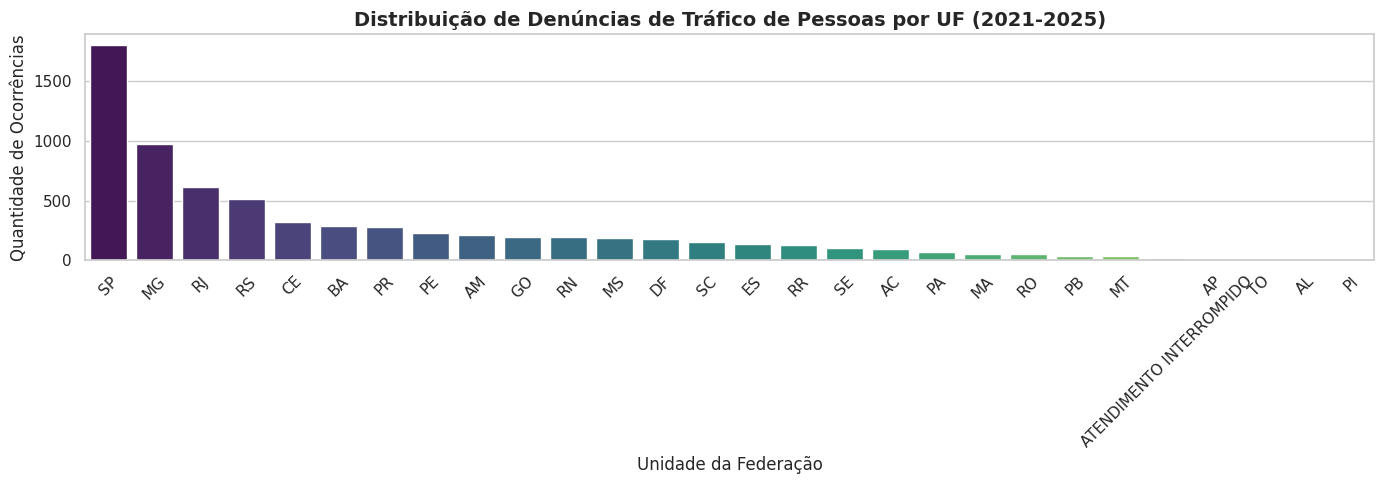

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurações globais de estilo de plotagem
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.unicode_minus"] = False

# 1. Distribuição de Casos por UF (Estado)
plt.figure(figsize=(14, 5))
order_uf = df_limpo['uf'].value_counts().index
sns.countplot(data=df_limpo, x='uf', order=order_uf, palette='viridis')
plt.title('Distribuição de Denúncias de Tráfico de Pessoas por UF (2021-2025)', fontsize=14, fontweight='bold')
plt.xlabel('Unidade da Federação', fontsize=12)
plt.ylabel('Quantidade de Ocorrências', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


/tmp/ipykernel_1124/3020082106.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_limpo, y='genero_da_vitima', order=order_genero, ax=axes[0], palette='pastel')
/tmp/ipykernel_1124/3020082106.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_limpo, y='faixa_etaria_da_vitima', order=order_faixa, ax=axes[1], palette='flare')


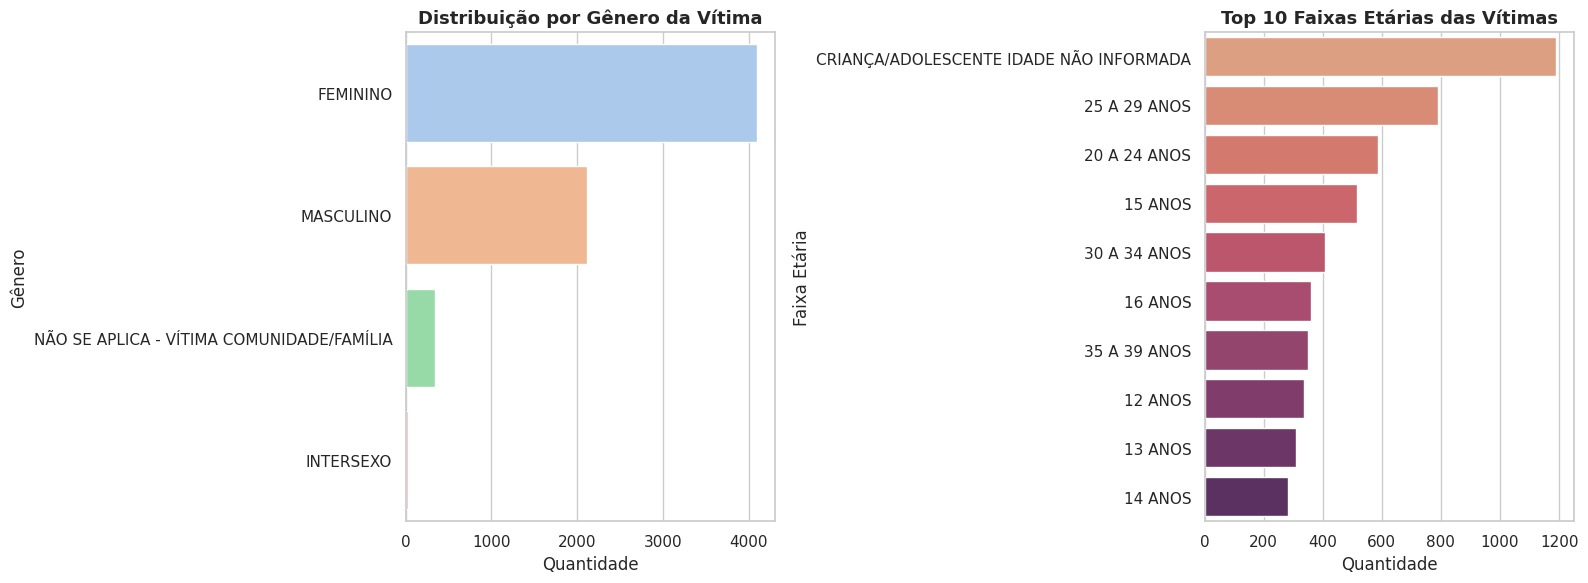

In [ ]:
# 2. Perfil das Vítimas: Gênero e Faixa Etária
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Gênero da Vítima
order_genero = df_limpo['genero_da_vitima'].value_counts().index
sns.countplot(data=df_limpo, y='genero_da_vitima', order=order_genero, ax=axes[0], palette='pastel')
axes[0].set_title('Distribuição por Gênero da Vítima', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Quantidade')
axes[0].set_ylabel('Gênero')

# Subplot 2: Faixa Etária da Vítima (Top 10 para evitar poluição visual)
order_faixa = df_limpo['faixa_etaria_da_vitima'].value_counts().head(10).index
sns.countplot(data=df_limpo, y='faixa_etaria_da_vitima', order=order_faixa, ax=axes[1], palette='flare')
axes[1].set_title('Top 10 Faixas Etárias das Vítimas', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Quantidade')
axes[1].set_ylabel('Faixa Etária')

plt.tight_layout()
plt.show()


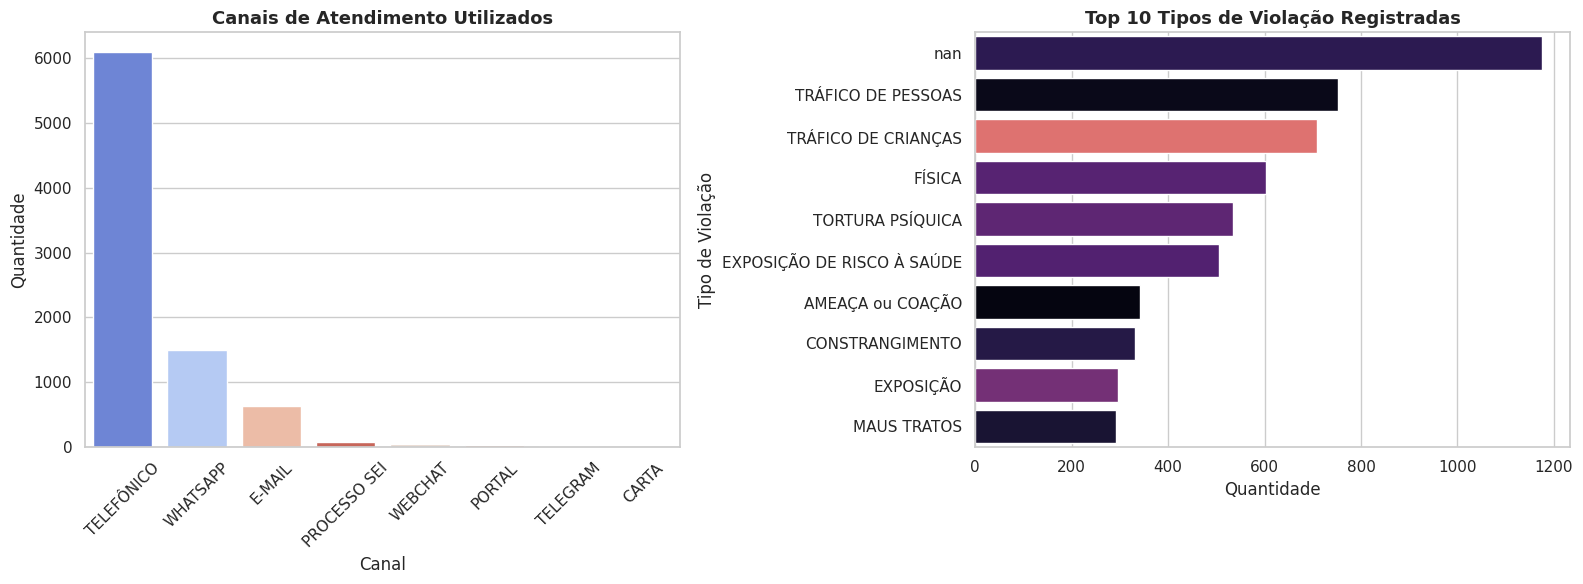

In [ ]:
# Recriando as colunas de taxonomia necessárias diretamente no df_limpo para garantir integridade
if 'violacao' in df_limpo.columns and 'violacao_nivel_3_normalizada' not in df_limpo.columns:
    df_limpo['violacao_nivel_3'] = df_limpo['violacao'].str.split(">").str[2] if 'violacao_nivel_3' not in df_limpo.columns else df_limpo['violacao_nivel_3']
    df_limpo[['violacao_nivel_3_normalizada', 'violacao_abrangencia']] = df_limpo['violacao_nivel_3'].astype(str).str.split(' - ', n=1, expand=True)

# 3. Canais de Atendimento e Tipo de Tráfego de Pessoas
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Canal de Atendimento
order_canal = df_limpo['canal_de_atendimento'].value_counts().index
sns.countplot(data=df_limpo, x='canal_de_atendimento', order=order_canal, ax=axes[0], hue='canal_de_atendimento', palette='coolwarm', legend=False)
axes[0].set_title('Canais de Atendimento Utilizados', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Canal')
axes[0].set_ylabel('Quantidade')
axes[0].tick_params(axis='x', rotation=45)

# Subplot 2: Nível 3 Normalizado da Violação (Top 10 mais recorrentes)
order_v_nivel3 = df_limpo['violacao_nivel_3_normalizada'].value_counts().head(10).index
sns.countplot(data=df_limpo, y='violacao_nivel_3_normalizada', order=order_v_nivel3, ax=axes[1], hue='violacao_nivel_3_normalizada', palette='magma', legend=False)
axes[1].set_title('Top 10 Tipos de Violação Registradas', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Quantidade')
axes[1].set_ylabel('Tipo de Violação')

plt.tight_layout()
plt.show()

### **Passo 5: Análise Bivariada e Multivariada**
Nesta etapa, cruzamos múltiplas variáveis chave do conjunto `df_limpo` para identificar padrões sistêmicos de vulnerabilidade, perfis de agressores e fluxos territoriais de tráfico.

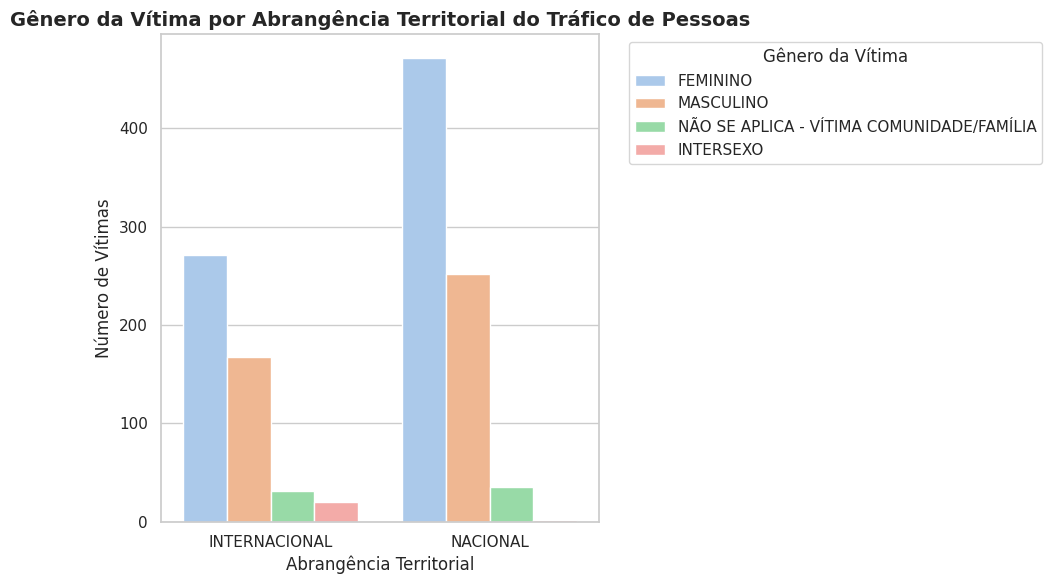

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Filtrando o DataFrame para registros onde temos a abrangência territorial (Nacional / Internacional)
df_abrangencia = df_limpo[df_limpo['violacao_abrangencia'].notna() & df_limpo['genero_da_vitima'].notna()]

# 1. Cruzamento: Gênero da Vítima vs Abrangência do Tráfico
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df_abrangencia,
    x='violacao_abrangencia',
    hue='genero_da_vitima',
    palette='pastel'
)
plt.title('Gênero da Vítima por Abrangência Territorial do Tráfico de Pessoas', fontsize=14, fontweight='bold')
plt.xlabel('Abrangência Territorial', fontsize=12)
plt.ylabel('Número de Vítimas', fontsize=12)
plt.legend(title='Gênero da Vítima', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


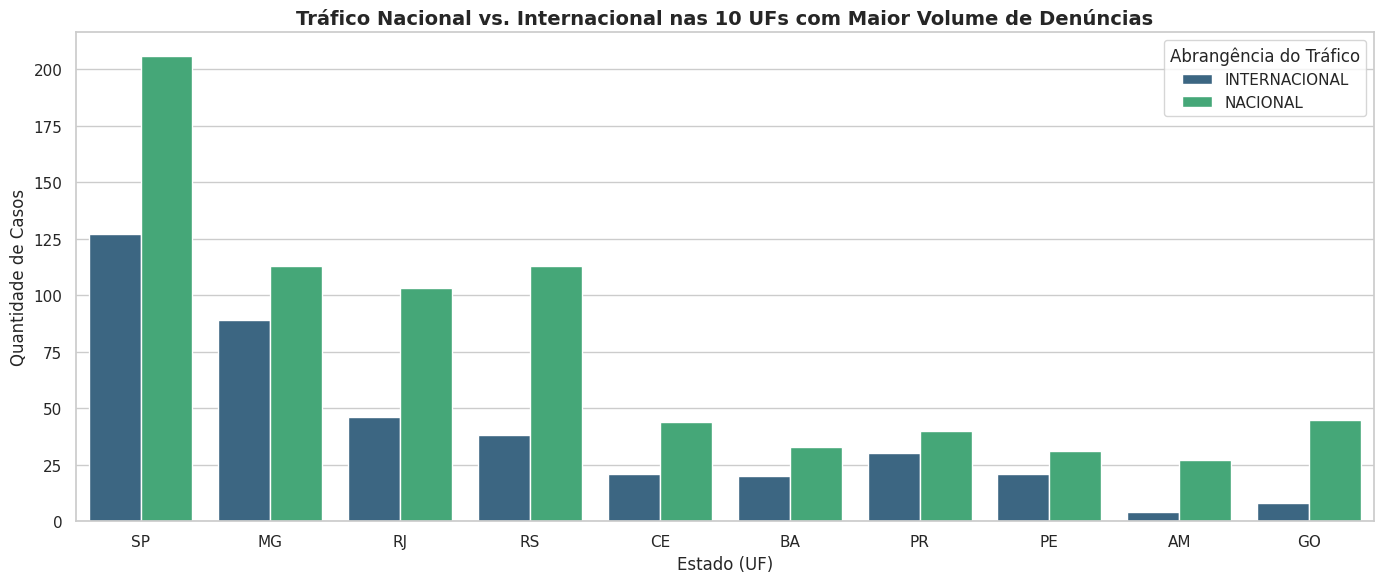

In [ ]:
# 2. Cruzamento: Estados (UFs) vs Abrangência do Tráfico (Top 10 UFs com mais casos)
top_10_ufs = df_limpo['uf'].value_counts().head(10).index
df_top_uf_abrangencia = df_limpo[df_limpo['uf'].isin(top_10_ufs) & df_limpo['violacao_abrangencia'].notna()]

plt.figure(figsize=(14, 6))
sns.countplot(
    data=df_top_uf_abrangencia,
    x='uf',
    hue='violacao_abrangencia',
    order=top_10_ufs,
    palette='viridis'
)
plt.title('Tráfico Nacional vs. Internacional nas 10 UFs com Maior Volume de Denúncias', fontsize=14, fontweight='bold')
plt.xlabel('Estado (UF)', fontsize=12)
plt.ylabel('Quantidade de Casos', fontsize=12)
plt.legend(title='Abrangência do Tráfico', loc='upper right')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### **Passo 6: Detecção de Outliers e Anomalias**
Nesta etapa, analisamos anomalias na coluna numérica `sl_quantidade_vitimas` e potenciais inconsistências temporais no registro das denúncias.

=== Estatísticas Descritivas: Qtd de Vítimas por Registro ===
count    8401.000000
mean        3.287704
std         7.467195
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        60.000000
Name: sl_quantidade_vitimas_num, dtype: float64


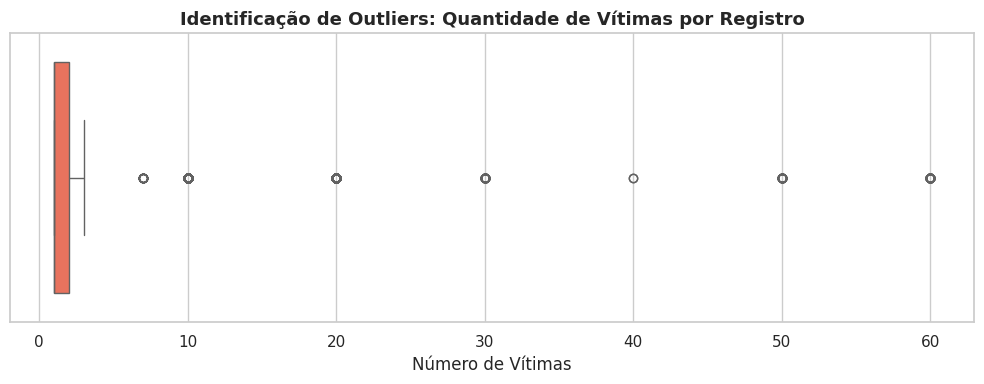


=== Registros com Quantidade Extrema de Vítimas (Acima ou igual a 60.0 vítimas) ===


,hash,uf,sl_quantidade_vitimas_num,violacao_nivel_3_normalizada
278,a7cc34dd65611fde2fa06c55ffa03b1b,MG,60,TRÁFICO DE PESSOAS
279,1c9ef0b20eaca2b2229cd832f1294e51,MG,60,nan
280,c28c100f83eed50ecbd6834f046e0491,MG,60,nan
284,683d2ff7a261492c663bcd2297548ea1,MG,60,nan
285,c28c100f83eed50ecbd6834f046e0491,MG,60,nan
...,...,...,...,...
628,fe98c48ce3636be263dab63e8b46ea49,CE,60,nan
631,fe98c48ce3636be263dab63e8b46ea49,CE,60,nan
632,f585bc8f7823850fb2b4ce43841d13d4,CE,60,EXTORSÃO MEDIANTE SEQUESTRO
633,f585bc8f7823850fb2b4ce43841d13d4,CE,60,AUTONOMIA DE VONTADE


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Converter a quantidade de vítimas para inteiro de forma segura
df_limpo['sl_quantidade_vitimas_num'] = pd.to_numeric(df_limpo['sl_quantidade_vitimas'], errors='coerce')

# 1. Estatística descritiva e detecção de outliers de quantidade de vítimas
print("=== Estatísticas Descritivas: Qtd de Vítimas por Registro ===")
print(df_limpo['sl_quantidade_vitimas_num'].describe())

# Boxplot para visualizar a distribuição e valores atípicos extremos
plt.figure(figsize=(10, 4))
sns.boxplot(data=df_limpo, x='sl_quantidade_vitimas_num', color='tomato')
plt.title('Identificação de Outliers: Quantidade de Vítimas por Registro', fontsize=13, fontweight='bold')
plt.xlabel('Número de Vítimas')
plt.tight_layout()
plt.show()

# Filtrar registros com quantidade excessiva de vítimas (ex: acima do percentil 99.9)
limiar_extremo = df_limpo['sl_quantidade_vitimas_num'].quantile(0.999)
casos_extremos = df_limpo[df_limpo['sl_quantidade_vitimas_num'] >= limiar_extremo]

# Definir as colunas de localização disponíveis de forma dinâmica
colunas_exibicao = ['hash', 'uf', 'sl_quantidade_vitimas_num', 'violacao_nivel_3_normalizada']
if 'municipio_nome' in df_limpo.columns:
    colunas_exibicao.insert(2, 'municipio_nome')

print(f"\n=== Registros com Quantidade Extrema de Vítimas (Acima ou igual a {limiar_extremo} vítimas) ===")
display(casos_extremos[colunas_exibicao])

In [ ]:
# Passo 7: Feature Engineering / Feature Selection
import pandas as pd
import numpy as np

print("=== Iniciando Engenharia de Atributos ===")

# 1. Extração de Componentes Temporais da data de cadastro
df_limpo['data_de_cadastro_dt'] = pd.to_datetime(df_limpo['data_de_cadastro'], errors='coerce', format='mixed')
df_limpo['cadastro_ano'] = df_limpo['data_de_cadastro_dt'].dt.year
df_limpo['cadastro_mes'] = df_limpo['data_de_cadastro_dt'].dt.month

print(f"- Atributos temporais criados: 'cadastro_ano' e 'cadastro_mes'")

# 2. Agrupamento de Faixas Etárias para simplificação analítica
def agrupar_faixa_etaria(faixa):
    if pd.isna(faixa):
        return np.nan
    faixa_upper = str(faixa).upper()
    if 'CRIANÇA' in faixa_upper or 'ADOLESCENTE' in faixa_upper or any(f'{i} ANOS' in faixa_upper for i in range(0, 18)):
        return 'Criança/Adolescente (0-17)'
    elif any(f'{i} ANOS' in faixa_upper for i in range(18, 60)) or '20 A 24' in faixa_upper or '25 A 29' in faixa_upper or '30 A 34' in faixa_upper or '35 A 39' in faixa_upper or '40 A 44' in faixa_upper or '45 A 49' in faixa_upper or '50 A 54' in faixa_upper or '55 A 59' in faixa_upper:
        return 'Adulto (18-59)'
    elif 'IDOSO' in faixa_upper or '60 ANOS' in faixa_upper or any(f'{i} ANOS' in faixa_upper for i in range(60, 110)):
        return 'Idoso (60+)'
    else:
        return 'Outros/Não Especificado'

df_limpo['faixa_etaria_agrupada'] = df_limpo['faixa_etaria_da_vitima'].apply(agrupar_faixa_etaria)

print("- Nova feature 'faixa_etaria_agrupada' criada com sucesso!")
print("\nDistribuição da Faixa Etária Agrupada:")
print(df_limpo['faixa_etaria_agrupada'].value_counts(dropna=False))

=== Iniciando Engenharia de Atributos ===
- Atributos temporais criados: 'cadastro_ano' e 'cadastro_mes'
- Nova feature 'faixa_etaria_agrupada' criada com sucesso!

Distribuição da Faixa Etária Agrupada:
faixa_etaria_agrupada
Criança/Adolescente (0-17)    7392
Outros/Não Especificado        534
NaN                            475
Name: count, dtype: int64


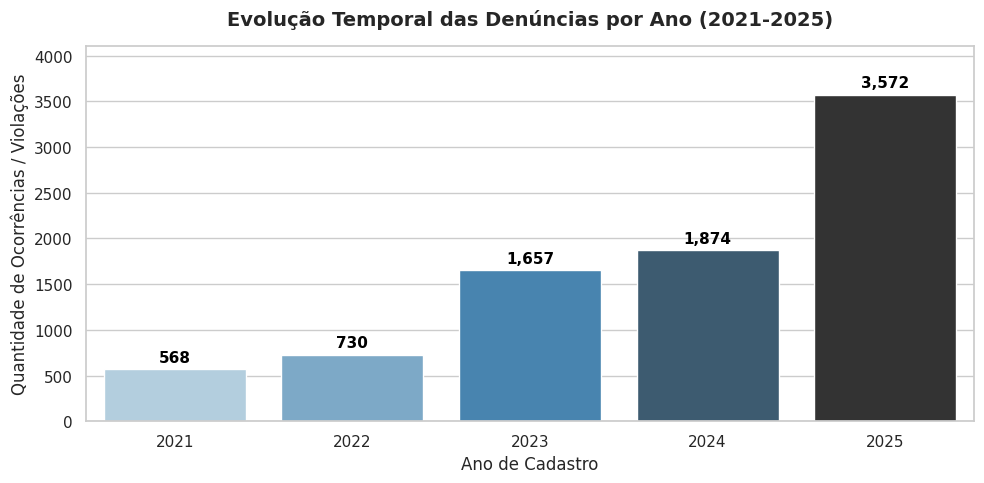

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Agrupar os dados por ano e contar o volume de denúncias (usando o hash único por denúncia ou total de registros)
# Como cada linha do df_limpo representa uma violação/registro dentro de uma denúncia:
evolucao_anual = df_limpo['cadastro_ano'].value_counts().sort_index().reset_index()
evolucao_anual.columns = ['Ano', 'Quantidade de Registros']

# 2. Criar a visualização
plt.figure(figsize=(10, 5))
sns.barplot(data=evolucao_anual, x='Ano', y='Quantidade de Registros', palette='Blues_d', hue='Ano', legend=False)

# Adicionar rótulos de valores no topo de cada barra para facilitar a leitura
for index, row in evolucao_anual.iterrows():
    plt.text(index, row['Quantidade de Registros'] + 80, f"{int(row['Quantidade de Registros']):,}",
             color='black', ha="center", fontsize=11, fontweight='bold')

plt.title('Evolução Temporal das Denúncias por Ano (2021-2025)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Ano de Cadastro', fontsize=12)
plt.ylabel('Quantidade de Ocorrências / Violações', fontsize=12)
plt.ylim(0, evolucao_anual['Quantidade de Registros'].max() * 1.15) # Ajustar limite do eixo Y para dar espaço aos rótulos
plt.tight_layout()
plt.show()

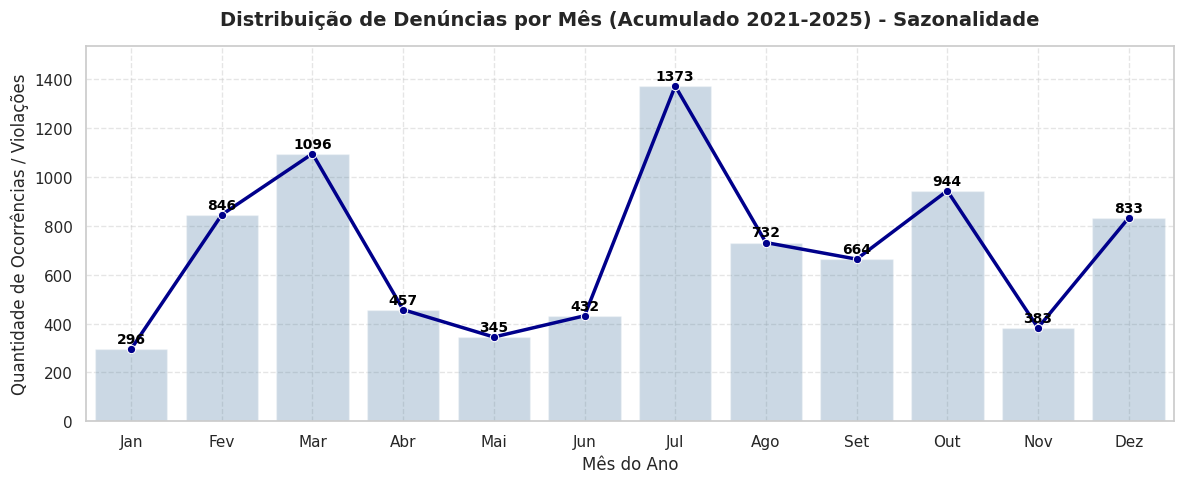

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Agrupar as denúncias por mês acumulado
distribuicao_mensal = df_limpo['cadastro_mes'].value_counts().sort_index().reset_index()
distribuicao_mensal.columns = ['Mês', 'Quantidade de Registros']

# Mapear os números para os nomes dos meses em português
meses_nomes = {
    1: 'Jan', 2: 'Fev', 3: 'Mar', 4: 'Abr', 5: 'Mai', 6: 'Jun',
    7: 'Jul', 8: 'Ago', 9: 'Set', 10: 'Out', 11: 'Nov', 12: 'Dez'
}
distribuicao_mensal['Nome_Mes'] = distribuicao_mensal['Mês'].map(meses_nomes)

# 2. Criar a visualização da sazonalidade
plt.figure(figsize=(12, 5))
sns.lineplot(data=distribuicao_mensal, x='Nome_Mes', y='Quantidade de Registros', marker='o', linewidth=2.5, color='darkblue', sort=False)
sns.barplot(data=distribuicao_mensal, x='Nome_Mes', y='Quantidade de Registros', alpha=0.3, color='steelblue')

# Adicionar rótulos com os valores em cada ponto
for index, row in distribuicao_mensal.iterrows():
    plt.text(index, row['Quantidade de Registros'] + 25, f"{int(row['Quantidade de Registros'])}",
             color='black', ha="center", fontsize=10, fontweight='bold')

plt.title('Distribuição de Denúncias por Mês (Acumulado 2021-2025) - Sazonalidade', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Mês do Ano', fontsize=12)
plt.ylabel('Quantidade de Ocorrências / Violações', fontsize=12)
plt.ylim(0, distribuicao_mensal['Quantidade de Registros'].max() * 1.12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

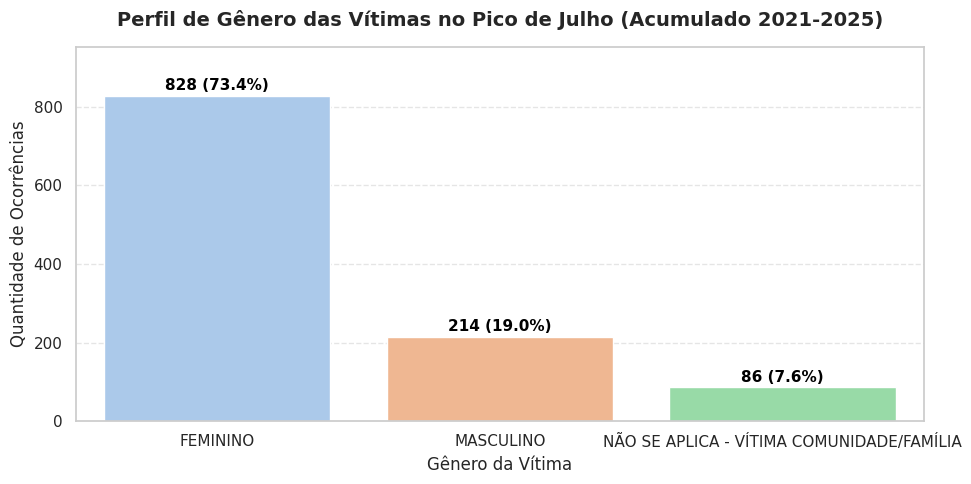

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filtrar os dados de df_limpo apenas para o mês de julho (cadastro_mes == 7) e com gênero não nulo
df_julho = df_limpo[(df_limpo['cadastro_mes'] == 7) & (df_limpo['genero_da_vitima'].notna())]

# Calcular a distribuição absoluta e percentual
distr_genero_julho = df_julho['genero_da_vitima'].value_counts().reset_index()
distr_genero_julho.columns = ['Gênero da Vítima', 'Quantidade']
distr_genero_julho['Porcentagem'] = (distr_genero_julho['Quantidade'] / distr_genero_julho['Quantidade'].sum() * 100).round(1)

# Criar a visualização
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=distr_genero_julho,
    x='Gênero da Vítima',
    y='Quantidade',
    palette='pastel',
    hue='Gênero da Vítima',
    legend=False
)

# Adicionar rótulos com a quantidade e a porcentagem no topo de cada barra
for i, row in distr_genero_julho.iterrows():
    plt.text(i, row['Quantidade'] + 15, f"{int(row['Quantidade'])} ({row['Porcentagem']}%)",
             color='black', ha="center", fontsize=11, fontweight='bold')

plt.title('Perfil de Gênero das Vítimas no Pico de Julho (Acumulado 2021-2025)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Gênero da Vítima', fontsize=12)
plt.ylabel('Quantidade de Ocorrências', fontsize=12)
plt.ylim(0, distr_genero_julho['Quantidade'].max() * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

=== Tabela de Frequência: Gênero vs Abrangência no Mês de Julho ===


genero_da_vitima,FEMININO,MASCULINO,NÃO SE APLICA - VÍTIMA COMUNIDADE/FAMÍLIA
violacao_abrangencia,,,
INTERNACIONAL,48,21,4
NACIONAL,47,17,7


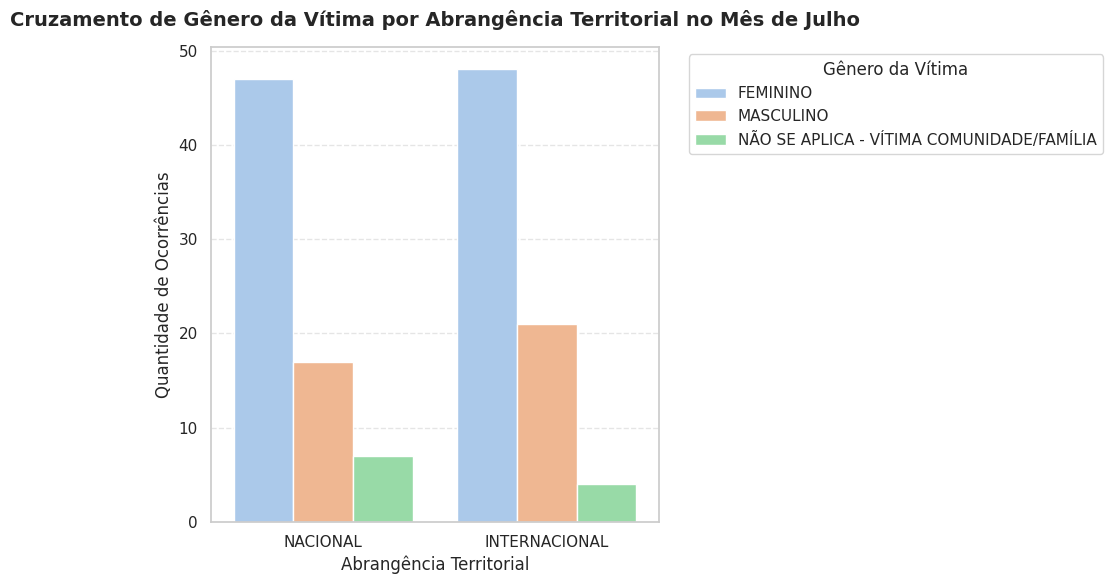

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filtrar dados para o mês de julho (7) onde gênero e abrangência não são nulos
df_julho_abrangencia = df_limpo[
    (df_limpo['cadastro_mes'] == 7) &
    (df_limpo['genero_da_vitima'].notna()) &
    (df_limpo['violacao_abrangencia'].notna())
]

# Criar tabela de contingência para ver os números exatos
tabela_cruzada = pd.crosstab(
    df_julho_abrangencia['violacao_abrangencia'],
    df_julho_abrangencia['genero_da_vitima']
)
print("=== Tabela de Frequência: Gênero vs Abrangência no Mês de Julho ===")
display(tabela_cruzada)

# Visualização gráfica
plt.figure(figsize=(10, 6))
sns.countplot(
    data=df_julho_abrangencia,
    x='violacao_abrangencia',
    hue='genero_da_vitima',
    palette='pastel'
)

plt.title('Cruzamento de Gênero da Vítima por Abrangência Territorial no Mês de Julho', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Abrangência Territorial', fontsize=12)
plt.ylabel('Quantidade de Ocorrências', fontsize=12)
plt.legend(title='Gênero da Vítima', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

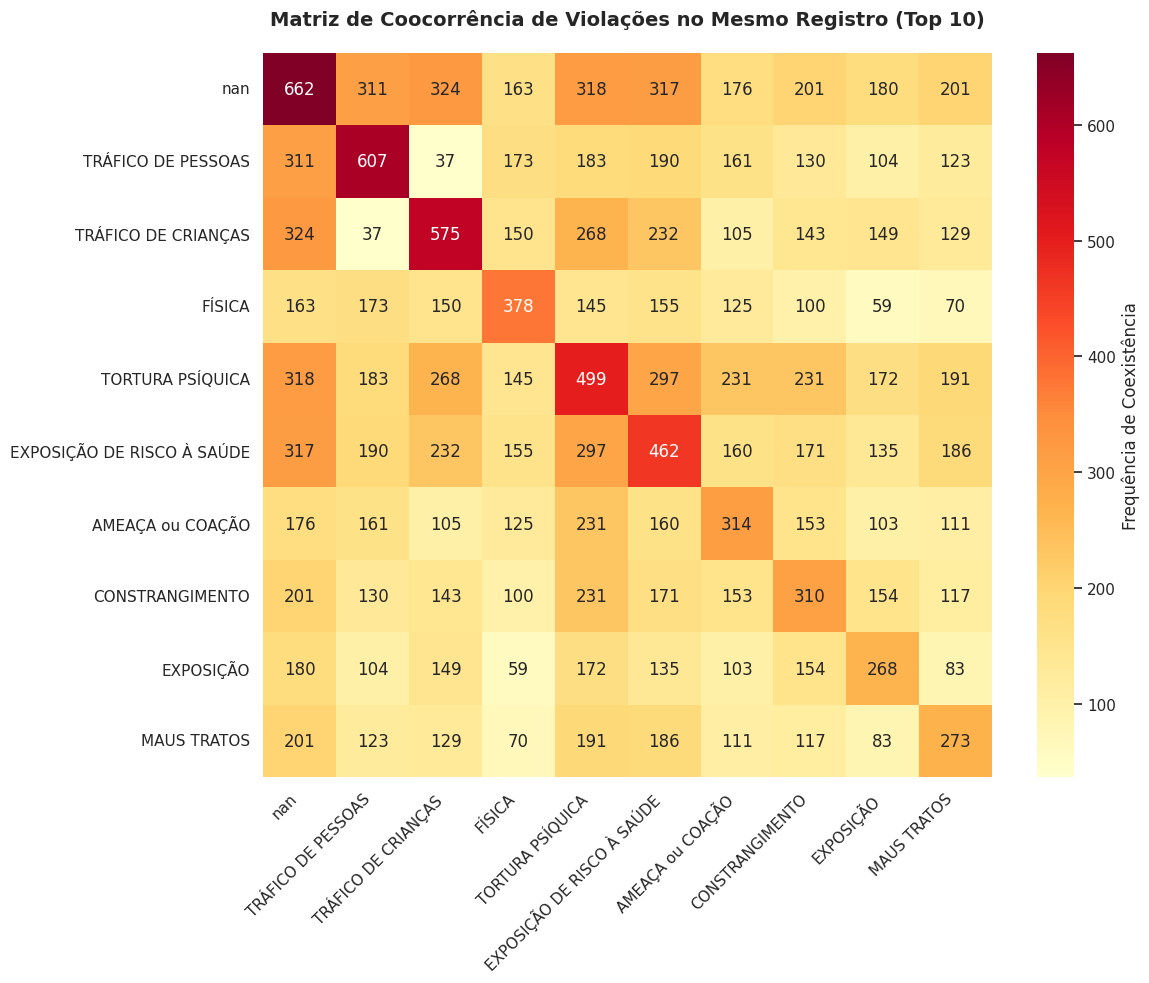

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from itertools import combinations

# 1. Filtrar registros válidos com hash e violação identificada
df_cooc = df_limpo[df_limpo['hash'].notna() & df_limpo['violacao_nivel_3_normalizada'].notna()]

# 2. Agrupar as violações por cada hash único (denúncia)
grupos_denuncias = df_cooc.groupby('hash')['violacao_nivel_3_normalizada'].apply(set).tolist()

# 3. Contar pares de coocorrência
pared_counts = Counter()
for violacoes in grupos_denuncias:
    if len(violacoes) > 1:
        # Gera todas as combinações de 2 a 2 ordenadas para evitar duplicatas espelhadas
        for comb in combinations(sorted(list(violacoes)), 2):
            pared_counts[comb] += 1

# 4. Encontrar as violações mais frequentes que coocorrem para focar o gráfico
top_violacoes = df_cooc['violacao_nivel_3_normalizada'].value_counts().head(10).index.tolist()

# 5. Criar a matriz de coocorrência para as top violações
matriz_cooc = pd.DataFrame(0, index=top_violacoes, columns=top_violacoes)

for (v1, v2), count in pared_counts.items():
    if v1 in top_violacoes and v2 in top_violacoes:
        matriz_cooc.at[v1, v2] = count
        matriz_cooc.at[v2, v1] = count  # A matriz é simétrica

# Preencher a diagonal com as contagens individuais de cada violação dentro de denúncias multi-violação
for v in top_violacoes:
    matriz_cooc.at[v, v] = sum(1 for grupo in grupos_denuncias if v in grupo)

# 6. Plotar o Heatmap de Coocorrência
plt.figure(figsize=(12, 10))
sns.heatmap(
    matriz_cooc,
    annot=True,
    fmt='d',
    cmap='YlOrRd',
    cbar_kws={'label': 'Frequência de Coexistência'}
)

plt.title('Matriz de Coocorrência de Violações no Mesmo Registro (Top 10)', fontsize=14, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

=== Top 15 Violações que mais Coocorrem com Casos de Tráfico ===


,Violação de Tráfico,Violação Coocorrente,Frequência
11,TRÁFICO DE CRIANÇAS,nan,324
15,TRÁFICO DE PESSOAS,nan,311
14,TRÁFICO DE CRIANÇAS,TORTURA PSÍQUICA,268
10,TRÁFICO DE CRIANÇAS,EXPOSIÇÃO DE RISCO À SAÚDE,232
25,TRÁFICO DE PESSOAS,EXPOSIÇÃO DE RISCO À SAÚDE,190
3,TRÁFICO DE PESSOAS,TORTURA PSÍQUICA,183
5,TRÁFICO DE PESSOAS,FÍSICA,173
0,TRÁFICO DE PESSOAS,AMEAÇA ou COAÇÃO,161
13,TRÁFICO DE CRIANÇAS,FÍSICA,150
21,TRÁFICO DE CRIANÇAS,EXPOSIÇÃO,149


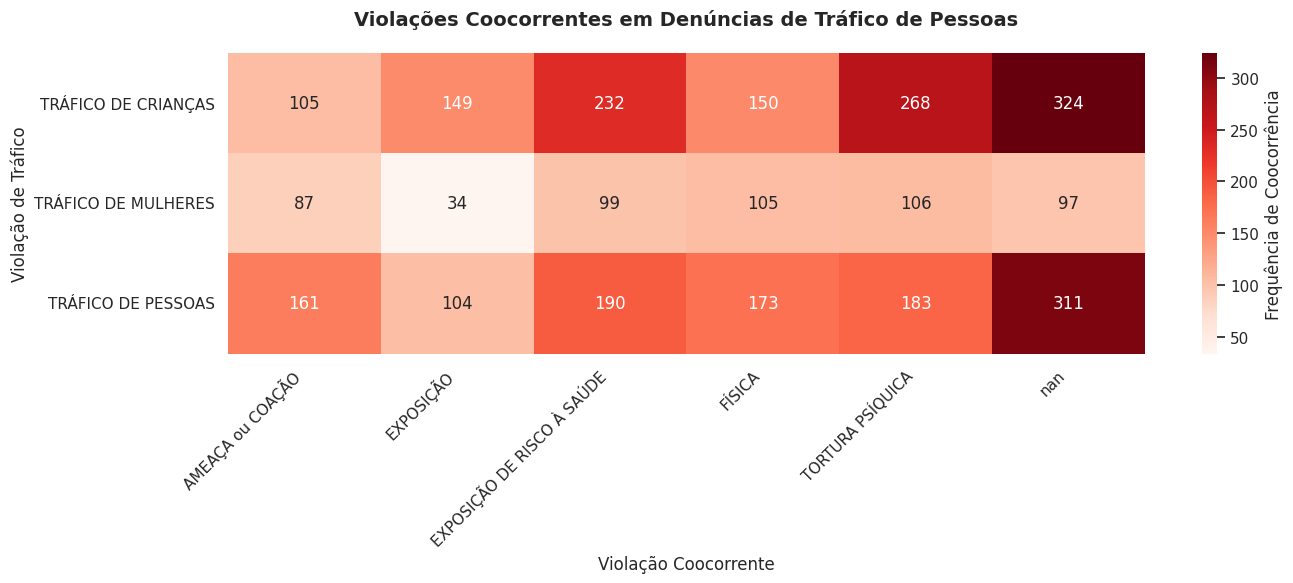

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# 1. Filtrar registros válidos com hash e violação identificada
df_cooc_target = df_limpo[df_limpo['hash'].notna() & df_limpo['violacao_nivel_3_normalizada'].notna()].copy()

# 2. Identificar quais hashes (denúncias) possuem pelo menos uma violação de TRÁFICO
# Filtra usando regex para capturar 'TRÁFICO' ou 'TRAFICO'
termo_trafico = 'TRÁ|AFICO'
hashes_com_trafico = df_cooc_target[
    df_cooc_target['violacao_nivel_3_normalizada'].str.contains(termo_trafico, regex=True, case=False)
]['hash'].unique()

# 3. Filtrar o dataset para conter apenas as denúncias que envolvem tráfico
df_trafico_relacionado = df_cooc_target[df_cooc_target['hash'].isin(hashes_com_trafico)]

# 4. Agrupar as violações por denúncia (hash)
grupos_trafico = df_trafico_relacionado.groupby('hash')['violacao_nivel_3_normalizada'].apply(set).tolist()

# 5. Mapear coocorrências: para cada denúncia com tráfico, listar as outras violações associadas
coocorrencias_com_trafico = Counter()

for violacoes in grupos_trafico:
    # Identifica as violações de tráfico na denúncia corrente
    violacoes_trafico_na_denuncia = {v for v in violacoes if pd.Series(v).str.contains(termo_trafico, regex=True, case=False).iloc[0]}
    # Identifica as outras violações (que não são as de tráfico mapeadas)
    outras_violacoes = violacoes - violacoes_trafico_na_denuncia

    for vt in violacoes_trafico_na_denuncia:
        for ov in outras_violacoes:
            coocorrencias_com_trafico[(vt, ov)] += 1

# 6. Converter o resultado para um DataFrame para melhor visualização
df_cooc_res = pd.DataFrame([
    {'Violação de Tráfico': vt, 'Violação Coocorrente': ov, 'Frequência': qtd}
    for (vt, ov), qtd in coocorrencias_com_trafico.items()
]).sort_values(by='Frequência', ascending=False)

print("=== Top 15 Violações que mais Coocorrem com Casos de Tráfico ===")
display(df_cooc_res.head(15))

# 7. Criar uma matriz/heatmap pivotada para as principais correlações
top_coocorrentes = df_cooc_res['Violação Coocorrente'].head(10).unique()
top_traficos = df_cooc_res['Violação de Tráfico'].unique()

df_pivot = df_cooc_res[
    df_cooc_res['Violação Coocorrente'].isin(top_coocorrentes)
].pivot(index='Violação de Tráfico', columns='Violação Coocorrente', values='Frequência').fillna(0).astype(int)

plt.figure(figsize=(14, 6))
sns.heatmap(df_pivot, annot=True, fmt='d', cmap='Reds', cbar_kws={'label': 'Frequência de Coocorrência'})
plt.title('Violações Coocorrentes em Denúncias de Tráfico de Pessoas', fontsize=14, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

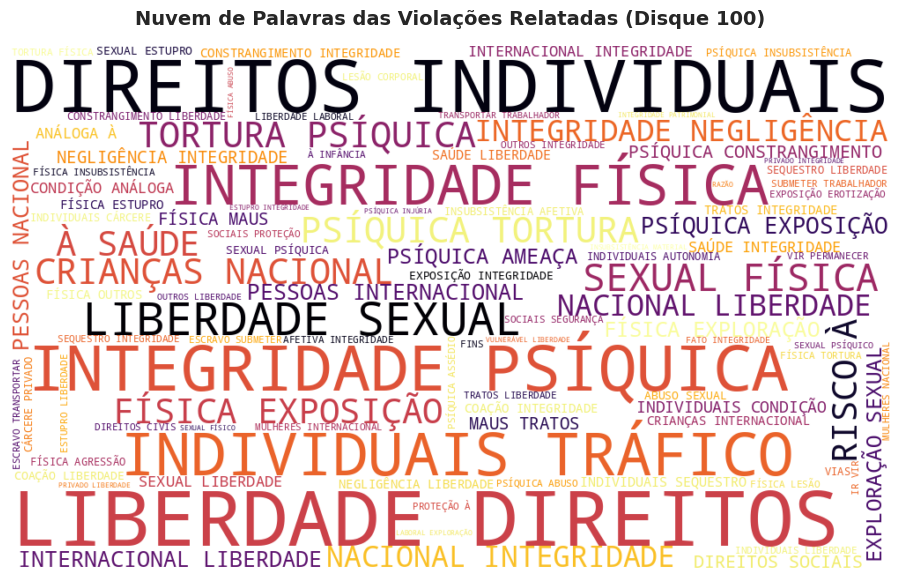

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
import pandas as pd

# 1. Obter todos os registros válidos da coluna 'violacao'
texto_violacoes = df_limpo['violacao'].dropna().astype(str)

# 2. Substituir o caractere '>' por espaços para separar as palavras corretamente
texto_processado = " ".join(texto_violacoes.str.replace('>', ' ', regex=False))

# Lista de stopwords em português para remover termos conectivos irrelevantes
stopwords_pt = {
    'de', 'a', 'o', 'que', 'e', 'do', 'da', 'em', 'um', 'para', 'com', 'não', 'uma', 'os', 'no', 'se', 'na', 'por', 'mais', 'as', 'dos', 'das', 'como', 'mas', 'ao', 'ele', 'ela', 'ou', 'u', 'ouros', 'outras', 'outro', 'outra', 'n/d', 'nan'
}

# 3. Gerar a nuvem de palavras
wordcloud = WordCloud(
    width=1000,
    height=600,
    background_color='white',
    stopwords=stopwords_pt,
    colormap='inferno',
    max_words=100,
    random_state=42
).generate(texto_processado)

# 4. Plotar a Nuvem de Palavras
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.title('Nuvem de Palavras das Violações Relatadas (Disque 100)', fontsize=14, fontweight='bold', pad=15)
plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

# Agrupar por tipo de violação normalizada e calcular a média e contagem de vítimas
media_vitimas_por_violacao = df_limpo.groupby('violacao_nivel_3_normalizada').agg(
    media_vitimas=('sl_quantidade_vitimas_num', 'mean'),
    total_ocorrencias=('sl_quantidade_vitimas_num', 'count')
).reset_index()

# Ordenar pela maior média de vítimas
media_vitimas_por_violacao = media_vitimas_por_violacao.sort_values(by='media_vitimas', ascending=False).reset_index(drop=True)

# Exibir a tabela formatada
print("=== Média de Vítimas por Tipo de Violação (Nível 3) ===")
display(media_vitimas_por_violacao.style.format({'media_vitimas': '{:.2f}'}))

=== Média de Vítimas por Tipo de Violação (Nível 3) ===


,violacao_nivel_3_normalizada,media_vitimas,total_ocorrencias
0,EXTORSÃO MEDIANTE SEQUESTRO,20.97,29
1,SITUAÇÃO DE RUA ou ABANDONO MATERIAL,13.88,8
2,IMPEDIMENTO DE TRABALHO/OFÍCIO/PROFISSÃO,10.00,1
3,DE CULTO,10.00,1
4,ALIENAÇÃO PARENTAL,6.30,20
5,nan,6.20,1175
6,TRÁFICO DE PESSOAS,5.90,753
7,PATRIMÔNIO MATERIAL,4.00,6
8,SEQUESTRO,3.99,238
9,CÁRCERE PRIVADO,3.73,139


### **Identificação de Relações com a Quantidade de Vítimas**
Como a maioria das nossas variáveis em `df_limpo` são categóricas, usaremos testes de hipótese não-paramétricos (Kruskal-Wallis) para verificar se a distribuição do número de vítimas difere significativamente entre as categorias de cada variável, além de calcular a correlação direta para as variáveis numéricas.

In [ ]:
%%capture
# Instalação da biblioteca especializada em codificadores de categorias
!pip install category_encoders

In [ ]:
import pandas as pd
import numpy as np
from category_encoders import TargetEncoder
from sklearn.model_selection import KFold

print("=== Aplicando Target Encoding em Variáveis de Alta Cardinalidade ===")

# 1. Definir as colunas categóricas de alta cardinalidade e o nosso alvo (target)
colunas_alta_cardinalidade = ['uf', 'municipio_da_vitima', 'sl_suspeito_municipio']
target_col = 'sl_quantidade_vitimas_num'

# Criando uma cópia para preservar o dataset original
df_encoded = df_limpo.copy()

# Remover registros onde o alvo é nulo para não prejudicar o encoding
df_encoded = df_encoded.dropna(subset=[target_col]).reset_index(drop=True)

# 2. Inicializar o TargetEncoder
# O parâmetro 'smoothing' ajuda a suavizar categorias com pouquíssimas amostras em direção à média global
te = TargetEncoder(cols=colunas_alta_cardinalidade, smoothing=10.0)

# 3. Ajustar e transformar (Fit & Transform)
# Em cenários reais de modelagem, você deve dar 'fit' apenas nos dados de TREINO e 'transform' no TREINO e TESTE.
# Aqui faremos no dataset completo para fins de exploração:
df_encoded[colunas_alta_cardinalidade] = te.fit_transform(df_encoded[colunas_alta_cardinalidade], df_encoded[target_col])

print("\nColunas transformadas com sucesso!")
display(df_encoded[['hash', target_col] + colunas_alta_cardinalidade].head(10))

=== Aplicando Target Encoding em Variáveis de Alta Cardinalidade ===


NameError: name 'df_limpo' is not defined

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Definição das variáveis preditoras (X) e variável alvo (y)
features = ['uf', 'municipio_da_vitima', 'sl_suspeito_municipio']
target = 'sl_quantidade_vitimas_num'

# Garantindo que não existam registros nulos nas features para o treinamento
df_model = df_encoded.dropna(subset=features + [target])

X = df_model[features]
y = df_model[target]

# 2. Divisão em Treino e Teste (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Inicialização e Treinamento do Modelo
modelo_lr = LinearRegression()
modelo_lr.fit(X_train, y_train)

# 4. Predições
y_pred_train = modelo_lr.predict(X_train)
y_pred_test = modelo_lr.predict(X_test)

# 5. Avaliação do Modelo
rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)

print("=== Desempenho do Modelo de Regressão Linear ===")
print(f"Treino - RMSE: {rmse_train:.4f} | R²: {r2_train:.4f}")
print(f"Teste  - RMSE: {rmse_test:.4f}  | R²: {r2_test:.4f}\n")

# 6. Coeficientes do Modelo
coeficientes = pd.DataFrame({
    'Atributo': features,
    'Coeficiente (Peso)': modelo_lr.coef_
})
coeficientes.loc[len(coeficientes)] = ['Intercepto (Vés)', modelo_lr.intercept_]

display(coeficientes)

=== Desempenho do Modelo de Regressão Linear ===
Treino - RMSE: 4.2582 | R²: 0.6878
Teste  - RMSE: 3.7262  | R²: 0.7009



,Atributo,Coeficiente (Peso)
0,uf,0.346912
1,municipio_da_vitima,0.932480
2,sl_suspeito_municipio,0.648299
3,Intercepto (Vés),-2.560145


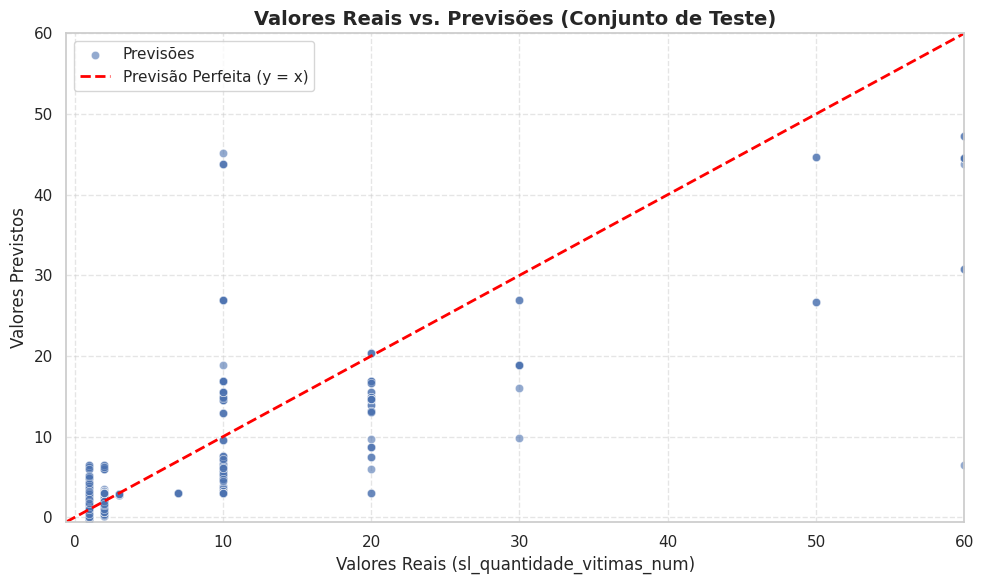

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Criando a visualização de Real vs. Previsto
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred_test, alpha=0.6, color='b', label='Previsões')

# Linha de identidade (onde y_test == y_pred_test, indicando previsão ideal)
lims = [min(y_test.min(), y_pred_test.min()), max(y_test.max(), y_pred_test.max())]
plt.plot(lims, lims, color='red', linestyle='--', linewidth=2, label='Previsão Perfeita (y = x)')

plt.title('Valores Reais vs. Previsões (Conjunto de Teste)', fontsize=14, fontweight='bold')
plt.xlabel('Valores Reais (sl_quantidade_vitimas_num)', fontsize=12)
plt.ylabel('Valores Previstos', fontsize=12)
plt.xlim(lims)
plt.ylim(lims)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### **Passo 9: Seleção de Atributos com LASSO e Modelagem Avançada**

Nesta etapa, implementaremos o pipeline solicitado:
1. **Feature Selection** usando `SelectFromModel` com um estimador `Lasso` (L1) para filtrar os atributos mais relevantes.
2. **Treinamento e Comparação de Modelos:** Testaremos os algoritmos **Random Forest**, **Gradient Boosting**, **XGBoost** e **LightGBM** para comparar suas performances contra o nosso baseline linear anterior.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LassoCV

# 1. Selecionando dinamicamente todas as colunas numéricas candidatas disponíveis como preditores
# Filtramos para usar apenas colunas com dados numéricos (já tratadas ou codificadas), excluindo a alvo
colunas_candidatas = df_encoded.select_dtypes(include=[np.number]).columns.tolist()
if target_col in colunas_candidatas:
    colunas_candidatas.remove(target_col)

# Filtrando linhas com nulos nas variáveis candidatas e alvo
df_ml = df_encoded.dropna(subset=colunas_candidatas + [target_col]).reset_index(drop=True)

X_full = df_ml[colunas_candidatas]
y_full = df_ml[target_col]

# Dividindo em treino e teste antes de qualquer seleção para evitar data leakage
X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(X_full, y_full, test_size=0.2, random_state=42)

# 2. Seleção de Atributos com LASSO
print("=== Seleção de Atributos com LASSO (L1) ===")
# Usamos LassoCV para encontrar o melhor parâmetro de regularização de forma automatizada via Cross-Validation
lasso_selector = SelectFromModel(LassoCV(cv=5, random_state=42))
lasso_selector.fit(X_train_f, y_train_f)

# Identificar colunas selecionadas pelo modelo
atributos_selecionados = np.array(colunas_candidatas)[lasso_selector.get_support()]
print(f"Total de atributos candidatos no dataset: {colunas_candidatas}")
print(f"Atributos efetivamente selecionados pelo LASSO: {list(atributos_selecionados)}\n")

# Filtrando os conjuntos de treino e teste para conter apenas as features selecionadas pelo LASSO
X_train_sel = lasso_selector.transform(X_train_f)
X_test_sel = lasso_selector.transform(X_test_f)


=== Seleção de Atributos com LASSO (L1) ===
Total de atributos candidatos no dataset: ['uf', 'municipio_da_vitima', 'sl_suspeito_municipio', 'cadastro_ano', 'cadastro_mes']
Atributos efetivamente selecionados pelo LASSO: [np.str_('uf'), np.str_('municipio_da_vitima'), np.str_('sl_suspeito_municipio'), np.str_('cadastro_ano'), np.str_('cadastro_mes')]



### **Passo 10: Criação do Pipeline de Pré-processamento e Modelagem Robusta**
Para evitar vazamento de dados (*data leakage*) e automatizar a preparação das variáveis categóricas restantes, vamos encapsular todo o fluxo de imputação e codificação categórica em um `Pipeline` e `ColumnTransformer` do Scikit-Learn.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_squared_error, r2_score
import xgboost as xgb

# 1. Preparação dos dados mantendo categóricas originais em vez do Target Encoding manual
target_col = 'sl_quantidade_vitimas_num'
df_pipeline = df_limpo.dropna(subset=[target_col]).reset_index(drop=True)

# Definir variáveis preditoras candidatas (vamos remover identificadores únicos e colunas redundantes)
colunas_descartar = ['hash', 'data_de_cadastro', 'data_de_cadastro_dt', 'sl_quantidade_vitimas', 'sl_quantidade_vitimas_num']
features_cols = [col for col in df_pipeline.columns if col not in colunas_descartar]

X_p = df_pipeline[features_cols]
y_p = df_pipeline[target_col]

# Divisão limpa em Treino e Teste
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(X_p, y_p, test_size=0.2, random_state=42)

# 2. Definição do Pipeline de Pré-processamento
categorical_cols = X_p.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_cols = X_p.select_dtypes(include=[np.number]).columns.tolist()

print(f"Variáveis Categóricas identificadas para o Pipeline ({len(categorical_cols)}): {categorical_cols[:5]}...")
print(f"Variáveis Numéricas identificadas para o Pipeline ({len(numerical_cols)}): {numerical_cols}")

# Transformador Categórico: Imputação por mais frequente + One-Hot Encoding robusto
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Transformador Numérico: Apenas preenchimento simples se necessário
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Combinador de pré-processamento para as colunas
preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_cols),
    ('cat', categorical_transformer, categorical_cols)
])

# 3. Pipeline Completo acoplado ao modelo preditivo principal (XGBoost)
pipeline_completo = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', xgb.XGBRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])

# Treinamento do pipeline de ponta a ponta
pipeline_completo.fit(X_train_p, y_train_p)

# Predições e avaliação
preds_test_p = pipeline_completo.predict(X_test_p)
rmse_p = np.sqrt(mean_squared_error(y_test_p, preds_test_p))
r2_p = r2_score(y_test_p, preds_test_p)

print("\n=== Avaliação do Pipeline com Pré-Processador Integrado ===")
print(f"Teste - RMSE: {rmse_p:.4f} | R²: {r2_p:.4f}")


NameError: name 'df_limpo' is not defined

### **Importância das Variáveis (Feature Importance) do Pipeline Final**

Nesta etapa, extraímos e mapeamos as importâncias atribuídas pelo modelo `XGBRegressor` às features após o pré-processamento. Devido à expansão do *One-Hot Encoding*, cada categoria individual das colunas categóricas é tratada como uma variável binária pelo modelo, o que nos permite identificar quais categorias específicas têm maior peso preditivo.

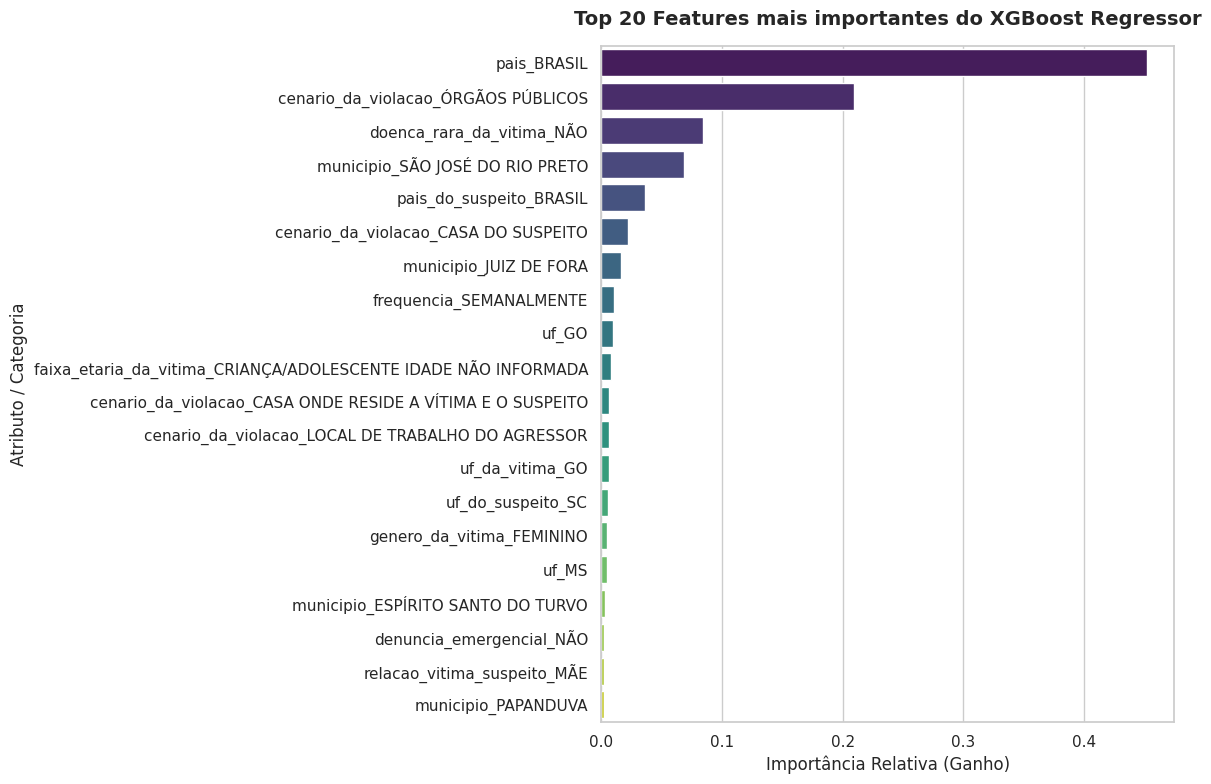


=== Tabela das Top 20 Importâncias ===


,Feature,Importance
54,pais_BRASIL,0.451813
45,cenario_da_violacao_ÓRGÃOS PÚBLICOS,0.209752
619,doenca_rara_da_vitima_NÃO,0.084280
400,municipio_SÃO JOSÉ DO RIO PRETO,0.068510
1040,pais_do_suspeito_BRASIL,0.036496
26,cenario_da_violacao_CASA DO SUSPEITO,0.022140
374,municipio_JUIZ DE FORA,0.016123
411,frequencia_SEMANALMENTE,0.010434
85,uf_GO,0.009501
605,faixa_etaria_da_vitima_CRIANÇA/ADOLESCENTE IDADE NÃO INFORMADA,0.008109


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# 1. Recuperar o pré-processador e o modelo treinado do pipeline
preprocessor_fitted = pipeline_completo.named_steps['preprocessor']
regressor_fitted = pipeline_completo.named_steps['regressor']

# 2. Obter os nomes das colunas numéricas (que não mudam de nome)
num_features = numerical_cols

# 3. Obter os nomes gerados pelo OneHotEncoder
cat_features_encoded = []
try:
    # Acessa o transformador categórico (segundo elemento do ColumnTransformer)
    cat_transformer = preprocessor_fitted.named_transformers_['cat']
    # Recupera o passo 'onehot'
    ohe = cat_transformer.named_steps['onehot']
    # Gera os novos nomes baseados nas colunas categóricas originais
    cat_features_encoded = ohe.get_feature_names_out(categorical_cols).tolist()
except Exception as e:
    print(f"Aviso ao mapear nomes das categóricas: {e}")
    # Fallback genérico caso falhe
    cat_features_encoded = [f"cat_feat_{i}" for i in range(regressor_fitted.feature_importances_.shape[0] - len(num_features))]

# Unir todas as colunas processadas na ordem exata em que foram alimentadas ao modelo
all_features_names = num_features + cat_features_encoded

# 4. Obter as importâncias do XGBoost
importances = regressor_fitted.feature_importances_

# Criar DataFrame para ordenação e filtragem
df_importances = pd.DataFrame({
    'Feature': all_features_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# 5. Plotar as Top 20 variáveis mais importantes para evitar saturação do gráfico
top_n = 20
plt.figure(figsize=(12, 8))
sns.barplot(
    data=df_importances.head(top_n),
    x='Importance',
    y='Feature',
    palette='viridis',
    hue='Feature',
    legend=False
)

plt.title(f'Top {top_n} Features mais importantes do XGBoost Regressor', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Importância Relativa (Ganho)', fontsize=12)
plt.ylabel('Atributo / Categoria', fontsize=12)
plt.tight_layout()
plt.show()

# Exibir a tabela com as importâncias em formato textual para consulta detalhada
print(f"\n=== Tabela das Top {top_n} Importâncias ===")
display(df_importances.head(top_n).style.format({'Importance': '{:.6f}'}))

In [ ]:
import pandas as pd
import numpy as np

print(f"Volume original de dados limpos (df_limpo): {df_limpo.shape[0]:,} linhas.")

# 1. Remover duplicatas exatas desconsiderando apenas o identificador único 'hash'
# Isso evita que o mesmo evento com hash diferente (ou registros de coocorrência idênticos) vaze entre treino e teste
colunas_sem_hash = [col for col in df_limpo.columns if col != 'hash']

df_sem_duplicatas = df_limpo.drop_duplicates(subset=colunas_sem_hash).reset_index(drop=True)

print(f"Volume após remover duplicatas (exceto hash): {df_sem_duplicatas.shape[0]:,} linhas.")
print(f"Total de linhas duplicadas removidas: {df_limpo.shape[0] - df_sem_duplicatas.shape[0]:,}")

Volume original de dados limpos (df_limpo): 8,401 linhas.
Volume após remover duplicatas (exceto hash): 7,119 linhas.
Total de linhas duplicadas removidas: 1,282


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_squared_error, r2_score
import xgboost as xgb
import numpy as np

# 1. Preparação dos dados sem duplicatas
target_col = 'sl_quantidade_vitimas_num'
df_pipeline_novo = df_sem_duplicatas.dropna(subset=[target_col]).reset_index(drop=True)

# Descartar identificadores e colunas derivadas do alvo
colunas_descartar = ['hash', 'data_de_cadastro', 'data_de_cadastro_dt', 'sl_quantidade_vitimas', 'sl_quantidade_vitimas_num']
features_cols = [col for col in df_pipeline_novo.columns if col not in colunas_descartar]

X_p_novo = df_pipeline_novo[features_cols]
y_p_novo = df_pipeline_novo[target_col]

# Divisão limpa em Treino e Teste (80% / 20%)
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_p_novo, y_p_novo, test_size=0.2, random_state=42
)

# 2. Definição do Pipeline de Pré-processamento
categorical_cols = X_p_novo.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_cols = X_p_novo.select_dtypes(include=[np.number]).columns.tolist()

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_cols),
    ('cat', categorical_transformer, categorical_cols)
])

# 3. Pipeline com o regressor XGBoost
pipeline_novo = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', xgb.XGBRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])

# Treinar o novo pipeline
pipeline_novo.fit(X_train_p, y_train_p)

# Predições e avaliação
preds_test_p = pipeline_novo.predict(X_test_p)
preds_train_p = pipeline_novo.predict(X_train_p)

rmse_test = np.sqrt(mean_squared_error(y_test_p, preds_test_p))
r2_test = r2_score(y_test_p, preds_test_p)
r2_train = r2_score(y_train_p, preds_train_p)

print("=== Novo Desempenho do Modelo (Sem Duplicatas) ===")
print(f"Treino - R²: {r2_train:.4f}")
print(f"Teste  - R²: {r2_test:.4f} | RMSE: {rmse_test:.4f}")

=== Novo Desempenho do Modelo (Sem Duplicatas) ===
Treino - R²: 0.9993
Teste  - R²: 0.9978 | RMSE: 0.3960


=== Comparação das Top 15 Features (Modelo Anterior vs. Modelo Novo) ===


,Feature,Importance_Anterior,Importance_Novo,Diferenca_Absoluta
0,pais_BRASIL,0.451813,0.315411,0.136402
1,doenca_rara_da_vitima_NÃO,0.084280,0.245517,0.161238
2,cenario_da_violacao_ÓRGÃOS PÚBLICOS,0.209752,0.171069,0.038683
3,pais_do_suspeito_BRASIL,0.036496,0.038783,0.002286
4,municipio_SÃO JOSÉ DO RIO PRETO,0.068510,0.031722,0.036787
5,cenario_da_violacao_LOCAL DE TRABALHO DO AGRESSOR,0.006224,0.028941,0.022717
6,cenario_da_violacao_CASA DO SUSPEITO,0.022140,0.025139,0.003000
7,uf_do_suspeito_SC,0.005384,0.018192,0.012808
8,frequencia_SEMANALMENTE,0.010434,0.015455,0.005021
9,municipio_JUIZ DE FORA,0.016123,0.014096,0.002027


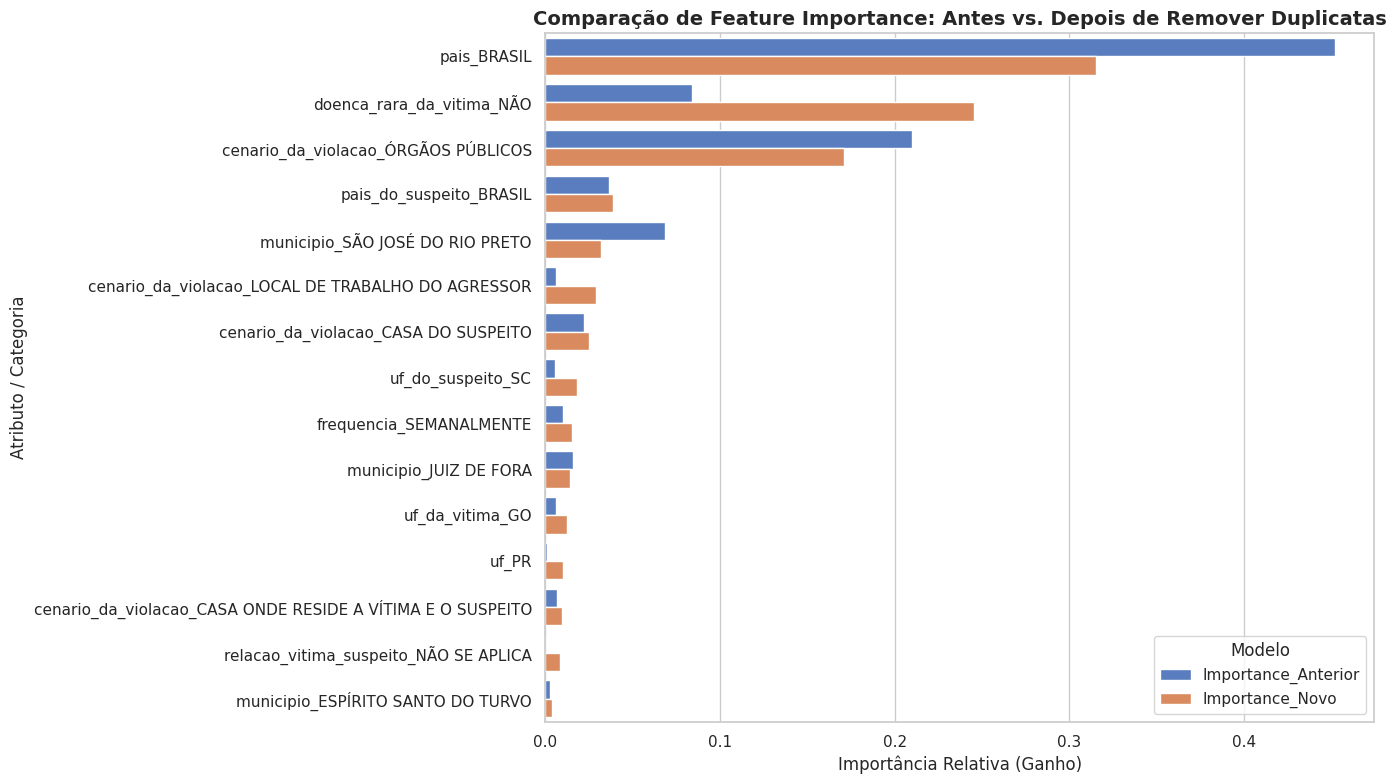

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Função para extrair as importâncias de um pipeline específico
def extrair_importancias(pipeline, prefixo):
    preprocessor = pipeline.named_steps['preprocessor']
    regressor = pipeline.named_steps['regressor']

    num_features = ['cadastro_ano', 'cadastro_mes']
    categorical_cols = [col for col in pipeline.feature_names_in_ if col not in num_features]

    try:
        cat_transformer = preprocessor.named_transformers_['cat']
        ohe = cat_transformer.named_steps['onehot']
        cat_features_encoded = ohe.get_feature_names_out(categorical_cols).tolist()
    except Exception:
        cat_features_encoded = [f"cat_{i}" for i in range(regressor.feature_importances_.shape[0] - len(num_features))]

    all_features = num_features + cat_features_encoded
    importances = regressor.feature_importances_

    return pd.DataFrame({
        'Feature': all_features,
        f'Importance_{prefixo}': importances
    })

# 2. Extrair importâncias dos dois pipelines
df_imp_anterior = extrair_importancias(pipeline_completo, 'Anterior')
df_imp_novo = extrair_importancias(pipeline_novo, 'Novo')

# 3. Mesclar os resultados para comparação
df_comparacao = pd.merge(df_imp_anterior, df_imp_novo, on='Feature', how='outer').fillna(0)
df_comparacao['Diferenca_Absoluta'] = (df_comparacao['Importance_Novo'] - df_comparacao['Importance_Anterior']).abs()
df_comparacao = df_comparacao.sort_values(by='Importance_Novo', ascending=False).reset_index(drop=True)

# Exibir a tabela com as top 15 variáveis do novo modelo e sua comparação com o anterior
print("=== Comparação das Top 15 Features (Modelo Anterior vs. Modelo Novo) ===")
display(df_comparacao.head(15).style.format({
    'Importance_Anterior': '{:.6f}',
    'Importance_Novo': '{:.6f}',
    'Diferenca_Absoluta': '{:.6f}'
}))

# 4. Plotar comparação visual lado a lado
df_plot = df_comparacao.head(15).melt(id_vars='Feature', value_vars=['Importance_Anterior', 'Importance_Novo'],
                                       var_name='Modelo', value_name='Importancia')

plt.figure(figsize=(14, 8))
sns.barplot(data=df_plot, y='Feature', x='Importancia', hue='Modelo', palette='muted')
plt.title('Comparação de Feature Importance: Antes vs. Depois de Remover Duplicatas', fontsize=14, fontweight='bold')
plt.xlabel('Importância Relativa (Ganho)', fontsize=12)
plt.ylabel('Atributo / Categoria', fontsize=12)
plt.tight_layout()
plt.show()

### **Ajuste do Modelo de Regressão Supervisionada para o Subconjunto de Tráfico (`TRÁ|AFICO`)**

Conforme as diretrizes de negócio:
1. **Filtragem:** Selecionamos apenas os registros onde a coluna `violacao` (ou `violacao_nivel_3_normalizada`) contém o termo correspondente a tráfico.
2. **Tratamento de Duplicatas:** Removemos registros duplicados desse subconjunto para evitar sobreajuste e vazamento de dados.
3. **Modelagem:** Treinamos o pipeline completo XGBoost focando estritamente nessa tipologia criminal.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_squared_error, r2_score
import xgboost as xgb

# 1. Filtrar estritamente pelo subconjunto de Tráfico
termo_trafico = 'TRÁ|AFICO'
df_supervisionado = df_limpo[
    df_limpo['violacao_nivel_3_normalizada'].astype(str).str.contains(termo_trafico, regex=True, case=False)
].copy()

print(f"Volume de registros de Tráfico antes da limpeza de duplicatas: {df_supervisionado.shape[0]:,} linhas.")

# 2. Remover duplicatas dentro deste subconjunto específico (desconsiderando a coluna 'hash')
colunas_sem_hash = [col for col in df_supervisionado.columns if col != 'hash']
df_supervisionado_limpo = df_supervisionado.drop_duplicates(subset=colunas_sem_hash).reset_index(drop=True)

print(f"Volume após remover duplicatas: {df_supervisionado_limpo.shape[0]:,} linhas.")

# 3. Preparação das Features (X) e Target (y)
target_col = 'sl_quantidade_vitimas_num'
df_supervisionado_limpo = df_supervisionado_limpo.dropna(subset=[target_col]).reset_index(drop=True)

colunas_descartar = ['hash', 'data_de_cadastro', 'data_de_cadastro_dt', 'sl_quantidade_vitimas', 'sl_quantidade_vitimas_num']
features_cols = [col for col in df_supervisionado_limpo.columns if col not in colunas_descartar]

X_sup = df_supervisionado_limpo[features_cols]
y_sup = df_supervisionado_limpo[target_col]

# Divisão Treino/Teste
X_train_sup, X_test_sup, y_train_sup, y_test_sup = train_test_split(
    X_sup, y_sup, test_size=0.2, random_state=42
)

# 4. Definição do Pré-processamento e Pipeline
categorical_cols = X_sup.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_cols = X_sup.select_dtypes(include=[np.number]).columns.tolist()

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

preprocessor_sup = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_cols),
    ('cat', categorical_transformer, categorical_cols)
])

# 5. Pipeline de Regressão
pipeline_trafico_sup = Pipeline(steps=[
    ('preprocessor', preprocessor_sup),
    ('regressor', xgb.XGBRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])

# Treinamento
pipeline_trafico_sup.fit(X_train_sup, y_train_sup)

# Avaliação
preds_test_sup = pipeline_trafico_sup.predict(X_test_sup)
rmse_sup = np.sqrt(mean_squared_error(y_test_sup, preds_test_sup))
r2_sup = r2_score(y_test_sup, preds_test_sup)

print("\n=== Desempenho do XGBoost no Subconjunto de Tráfico ===")
print(f"R² no Teste: {r2_sup:.4f}")
print(f"RMSE no Teste: {rmse_sup:.4f}")


Volume de registros de Tráfico antes da limpeza de duplicatas: 1,673 linhas.
Volume após remover duplicatas: 1,461 linhas.

=== Desempenho do XGBoost no Subconjunto de Tráfico ===
R² no Teste: 0.9528
RMSE no Teste: 1.6392


### **Feature Selection no Subconjunto de Tráfico de Pessoas**
Nesta etapa, utilizamos a seletividade de atributos para otimizar a dimensionalidade do modelo XGBoost ajustado para o Tráfico de Pessoas, reduzindo a complexidade de variáveis redundantes criadas no *One-Hot Encoding*.

### **Ajuste de Hiperparâmetros (Tuning) de Modelos via GridSearchCV**

Nesta seção, estruturamos uma busca exaustiva por parâmetros para otimizar os modelos de regressão linear e baseados em árvores, integrando pré-processamento, seleção de atributos e validação cruzada para mitigar o risco de sobreajuste (overfitting).

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import mean_squared_error, r2_score

# Modelos Candidatos
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import xgboost as xgb
import lightgbm as lgb

# 1. Preparação dos dados usando o subconjunto de Tráfico limpo de duplicatas
target_col = 'sl_quantidade_vitimas_num'
df_tuning = df_supervisionado_limpo.dropna(subset=[target_col]).reset_index(drop=True)

colunas_descartar = ['hash', 'data_de_cadastro', 'data_de_cadastro_dt', 'sl_quantidade_vitimas', 'sl_quantidade_vitimas_num']
features_cols = [col for col in df_tuning.columns if col not in colunas_descartar]

X_tune = df_tuning[features_cols]
y_tune = df_tuning[target_col]

X_train_t, X_test_tune, y_train_t, y_test_tune = train_test_split(
    X_tune, y_tune, test_size=0.2, random_state=42
)

# 2. Definição do Pré-processamento
categorical_cols = X_tune.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_cols = X_tune.select_dtypes(include=[np.number]).columns.tolist()

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_cols),
    ('cat', categorical_transformer, categorical_cols)
])

In [ ]:
print("=== Configurando GridSearch para os Modelos Candidatos ===")

# Dicionário de pipelines baseados em um estimador inicial e grids de hiperparâmetros específicos
grids_modelos = {
    'Ridge Regression': {
        'model': Ridge(random_state=42),
        'params': {
            'regressor__alpha': [0.1, 1.0, 10.0]
        }
    },
    'Random Forest': {
        'model': RandomForestRegressor(random_state=42, n_jobs=-1),
        'params': {
            'regressor__n_estimators': [50, 100],
            'regressor__max_depth': [10, 20, None]
        }
    },
    'Gradient Boosting': {
        'model': GradientBoostingRegressor(random_state=42),
        'params': {
            'regressor__n_estimators': [50, 100],
            'regressor__learning_rate': [0.05, 0.1],
            'regressor__max_depth': [3, 5]
        }
    },
    'XGBoost': {
        'model': xgb.XGBRegressor(random_state=42, n_jobs=-1),
        'params': {
            'regressor__n_estimators': [50, 100],
            'regressor__learning_rate': [0.05, 0.1],
            'regressor__max_depth': [3, 6]
        }
    },
    'LightGBM': {
        'model': lgb.LGBMRegressor(random_state=42, verbose=-1, n_jobs=-1),
        'params': {
            'regressor__n_estimators': [50, 100],
            'regressor__learning_rate': [0.05, 0.1],
            'regressor__num_leaves': [15, 31]
        }
    }
}

resultados_tuning = []

for nome, config in grids_modelos.items():
    print(f"\nOtimizando {nome}...")

    # Montamos o pipeline unificado contendo o ColumnTransformer, o seletor Lasso e o regressor
    # Usamos um Lasso simples no SelectFromModel para selecionar features de forma dinâmica antes de passar ao modelo final
    pipeline_tuning = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('selector', SelectFromModel(xgb.XGBRegressor(n_estimators=50, random_state=42, n_jobs=-1), threshold='mean')),
        ('regressor', config['model'])
    ])

    # Executamos o GridSearch com Validação Cruzada de 3 dobras (folds) para agilidade no processamento
    grid_search = GridSearchCV(
        pipeline_tuning,
        param_grid=config['params'],
        cv=3,
        scoring='neg_mean_squared_error',
        n_jobs=-1
    )

    # Treinamento
    grid_search.fit(X_train_t, y_train_t)

    # Melhores predições
    melhor_modelo = grid_search.best_estimator_
    preds_test = melhor_modelo.predict(X_test_tune)

    # Métricas de avaliação baseadas no melhor estimador
    rmse_te = np.sqrt(mean_squared_error(y_test_tune, preds_test))
    r2_te = r2_score(y_test_tune, preds_test)

    resultados_tuning.append({
        'Modelo': nome,
        'Melhores Parâmetros': grid_search.best_params_,
        'RMSE Teste (Otimizado)': rmse_te,
        'R² Teste (Otimizado)': r2_te
    })

    print(f"✓ {nome} concluído. Melhor R²: {r2_te:.4f}")

# Exibir a tabela consolidada de comparação pós-tuning
df_resultados_tuning = pd.DataFrame(resultados_tuning).sort_values(by='RMSE Teste (Otimizado)')
display(df_resultados_tuning)

=== Configurando GridSearch para os Modelos Candidatos ===

Otimizando Ridge Regression...
✓ Ridge Regression concluído. Melhor R²: 0.7133

Otimizando Random Forest...
✓ Random Forest concluído. Melhor R²: 0.9248

Otimizando Gradient Boosting...
✓ Gradient Boosting concluído. Melhor R²: 0.9221

Otimizando XGBoost...
✓ XGBoost concluído. Melhor R²: 0.9245

Otimizando LightGBM...
✓ LightGBM concluído. Melhor R²: 0.8461


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Modelo,Melhores Parâmetros,RMSE Teste (Otimizado),R² Teste (Otimizado)
1,Random Forest,"{'regressor__max_depth': None, 'regressor__n_e...",2.070004,0.924804
3,XGBoost,"{'regressor__learning_rate': 0.05, 'regressor_...",2.073916,0.924520
2,Gradient Boosting,"{'regressor__learning_rate': 0.05, 'regressor_...",2.107451,0.922059
4,LightGBM,"{'regressor__learning_rate': 0.1, 'regressor__...",2.961155,0.846124
0,Ridge Regression,{'regressor__alpha': 1.0},4.041819,0.713316


### **Parte 11: Pipeline de Modelagem Não Supervisionada (Clustering)**

Nesta etapa, implementaremos um pipeline de agrupamento utilizando o algoritmo **K-Means**. Como o nosso dataset contém uma combinação rica de colunas categóricas de alta cardinalidade e atributos numéricos, o fluxo será:
1. **Pré-processamento:** Imputação e codificação *One-Hot* via `ColumnTransformer`.
2. **Redução de Dimensionalidade (Opcional, mas recomendada para K-Means):** Utilização de `TruncatedSVD` (apropriado para matrizes esparsas pós-OHE) para consolidar a variância espacial.
3. **Método do Cotovelo (Elbow Method):** Avaliação da inércia para determinar o número ideal de clusters ($K$).

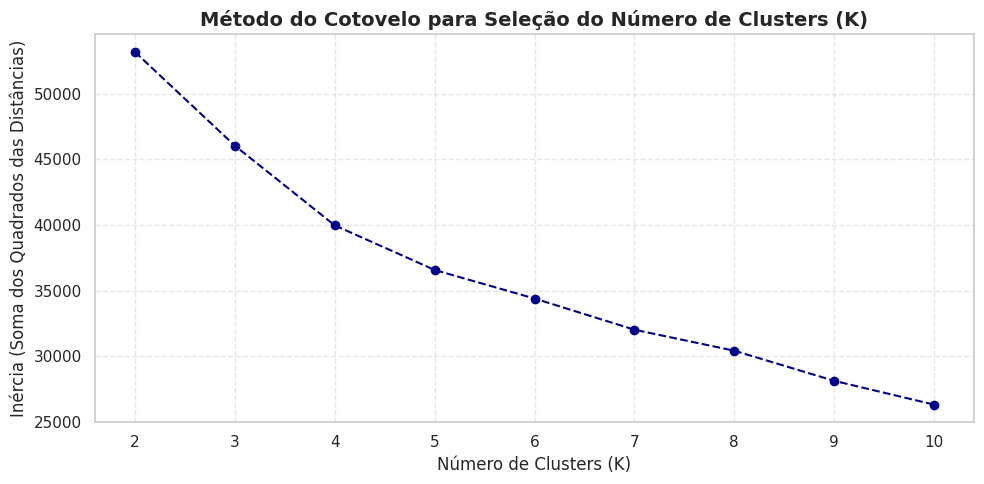

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans

# 1. Preparar os preditores categóricos e numéricos para o agrupamento
# Vamos desconsiderar apenas o hash para agrupar com base no perfil comportamental e geográfico
colunas_descartar_clustering = ['hash', 'data_de_cadastro', 'data_de_cadastro_dt', 'sl_quantidade_vitimas']
features_clustering = [col for col in df_limpo.columns if col not in colunas_descartar_clustering]

X_cluster = df_limpo[features_clustering].copy()

categorical_cols = X_cluster.select_dtypes(include=['object', 'category']).columns.tolist()
numerical_cols = X_cluster.select_dtypes(include=[np.number]).columns.tolist()

# 2. Pipeline de Pré-processamento e normalização espacial para Clustering
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=True))
])

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor_clustering = ColumnTransformer(transformers=[
    ('num', numerical_transformer, numerical_cols),
    ('cat', categorical_transformer, categorical_cols)
])

# Aplicar pré-processador
X_processed = preprocessor_clustering.fit_transform(X_cluster)

# 3. Reduzir dimensionalidade com TruncatedSVD para estabilizar o K-Means em alta dimensionalidade
svd = TruncatedSVD(n_components=10, random_state=42)
X_reduced = svd.fit_transform(X_processed)

# 4. Executar o Método do Cotovelo para encontrar o K ideal
inertias = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_reduced)
    inertias.append(kmeans.inertia_)

# Plotar a curva de Inércia
plt.figure(figsize=(10, 5))
plt.plot(K_range, inertias, marker='o', linestyle='--', color='darkblue')
plt.title('Método do Cotovelo para Seleção do Número de Clusters (K)', fontsize=14, fontweight='bold')
plt.xlabel('Número de Clusters (K)', fontsize=12)
plt.ylabel('Inércia (Soma dos Quadrados das Distâncias)', fontsize=12)
plt.xticks(K_range)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### **Parte 12: Ajuste Definitivo do K-Means (K=4) e Caracterização dos Perfis**

Agora que selecionamos o número ideal de grupos ($K=4$), vamos treinar o modelo final utilizando as 10 dimensões reduzidas pelo `TruncatedSVD`. Em seguida, salvaremos a identificação do cluster de cada denúncia de volta no DataFrame `df_limpo` para interpretar as principais características de cada grupo.

In [ ]:
# 1. Treinamento definitivo com o K escolhido (K=4)
k_ideal = 4
kmeans_final = KMeans(n_clusters=k_ideal, random_state=42, n_init=10)
clusters_labels = kmeans_final.fit_predict(X_reduced)

# 2. Atribuir os clusters ao DataFrame original para análise sociodemográfica
df_limpo['cluster_id'] = clusters_labels
print(f"=== Distribuição dos Perfis nos {k_ideal} Clusters Identificados ===")
distribuicao_clusters = df_limpo['cluster_id'].value_counts().reset_index()
distribuicao_clusters.columns = ['ID do Cluster', 'Quantidade de Registros']
distribuicao_clusters['Porcentagem (%)'] = (distribuicao_clusters['Quantidade de Registros'] / len(df_limpo) * 100).round(2)
display(distribuicao_clusters)

# 3. Análise rápida do perfil geográfico e gênero por cluster
print("\n=== Cruzamento de Gênero da Vítima por Cluster (Percentual) ===")
cruzamento_genero = pd.crosstab(df_limpo['cluster_id'], df_limpo['genero_da_vitima'], normalize='index') * 100
display(cruzamento_genero.round(2))

=== Distribuição dos Perfis nos 4 Clusters Identificados ===


,ID do Cluster,Quantidade de Registros,Porcentagem (%)
0,0,3373,40.15
1,2,2482,29.54
2,3,1599,19.03
3,1,947,11.27



=== Cruzamento de Gênero da Vítima por Cluster (Percentual) ===


genero_da_vitima,FEMININO,INTERSEXO,MASCULINO,NÃO SE APLICA - VÍTIMA COMUNIDADE/FAMÍLIA
cluster_id,,,,
0,76.66,0.44,16.66,6.24
1,69.98,0.00,30.02,0.00
2,50.57,0.05,42.18,7.19
3,45.44,1.51,50.41,2.64


=== Iniciando Caracterização Avançada dos Perfis (Clusters) ===

--- 1. Perfil Etário por Cluster (Percentual %) ---


faixa_etaria_agrupada,Criança/Adolescente (0-17),Outros/Não Especificado
cluster_id,,
0,91.00,9.00
1,85.42,14.58
2,93.70,6.30
3,100.00,0.00



--- 2. Top 5 Estados (UFs) de Ocorrência por Cluster ---

📍 Cluster 0:


,Qtd Denúncias,Representatividade (%)
uf,,
SP,658,20.31
MG,369,11.39
RJ,367,11.33
CE,221,6.82
BA,180,5.56



📍 Cluster 1:


,Qtd Denúncias,Representatividade (%)
uf,,
SP,220,27.33
MG,132,16.40
RJ,94,11.68
CE,69,8.57
GO,50,6.21


... (9 outputs left out)

,Qtd Violações,Representatividade (%)
violacao_nivel_3_normalizada,,
nan,370,14.91
TRÁFICO DE CRIANÇAS,286,11.52
FÍSICA,240,9.67
TRÁFICO DE PESSOAS,227,9.15
EXPOSIÇÃO DE RISCO À SAÚDE,169,6.81



🔥 Cluster 3:


,Qtd Violações,Representatividade (%)
violacao_nivel_3_normalizada,,
TRÁFICO DE PESSOAS,131,8.19
TORTURA PSÍQUICA,119,7.44
CONDIÇÃO ANÁLOGA À DE ESCRAVO,116,7.25
AMEAÇA ou COAÇÃO,106,6.63
nan,99,6.19


<Figure size 1200x500 with 0 Axes>

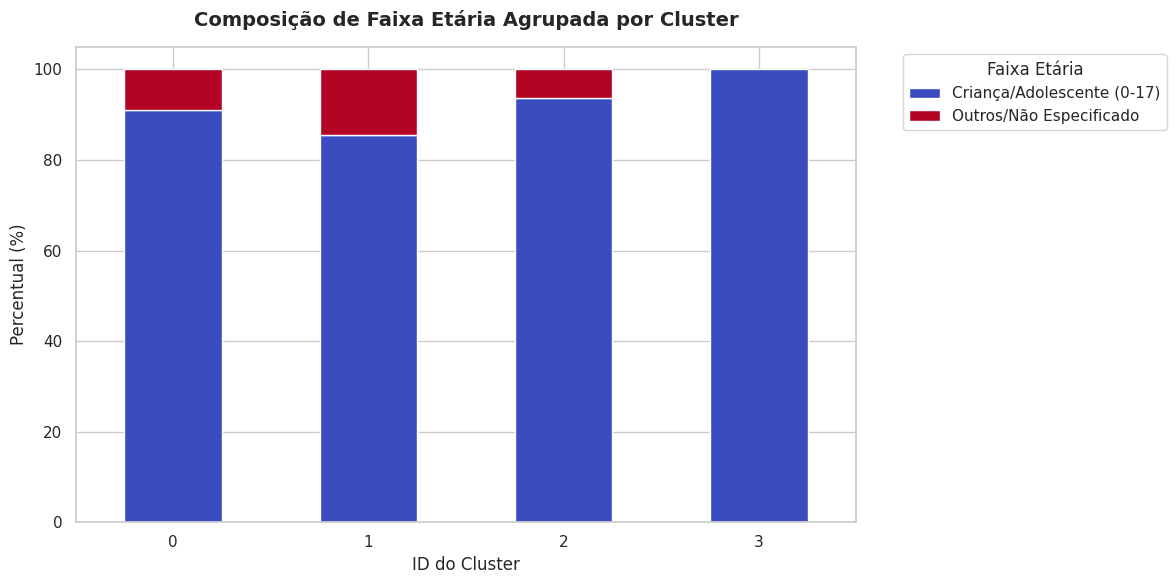

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("=== Iniciando Caracterização Avançada dos Perfis (Clusters) ===\n")

# 1. Cruzamento: Cluster vs Faixa Etária Agrupada
print("--- 1. Perfil Etário por Cluster (Percentual %) ---")
cruzamento_etario = pd.crosstab(df_limpo['cluster_id'], df_limpo['faixa_etaria_agrupada'], normalize='index') * 100
display(cruzamento_etario.round(2))

# 2. Cruzamento: Cluster vs Top 5 UFs mais frequentes
print("\n--- 2. Top 5 Estados (UFs) de Ocorrência por Cluster ---")
top_ufs_por_cluster = {}
for cid in sorted(df_limpo['cluster_id'].unique()):
    sub_df = df_limpo[df_limpo['cluster_id'] == cid]
    top_ufs = sub_df['uf'].value_counts(dropna=True).head(5)
    top_ufs_pct = (sub_df['uf'].value_counts(dropna=True, normalize=True).head(5) * 100).round(2)

    # Unir contagem e percentual para exibição limpa
    res_uf = pd.DataFrame({
        'Qtd Denúncias': top_ufs,
        'Representatividade (%)': top_ufs_pct
    })
    print(f"\n📍 Cluster {cid}:")
    display(res_uf)

# 3. Cruzamento: Cluster vs Top 5 Tipos de Violação
print("\n--- 3. Top 5 Tipologias de Violação (Nível 3) por Cluster ---")
for cid in sorted(df_limpo['cluster_id'].unique()):
    sub_df = df_limpo[df_limpo['cluster_id'] == cid]
    top_viols = sub_df['violacao_nivel_3_normalizada'].value_counts(dropna=True).head(5)
    top_viols_pct = (sub_df['violacao_nivel_3_normalizada'].value_counts(dropna=True, normalize=True).head(5) * 100).round(2)

    res_viol = pd.DataFrame({
        'Qtd Violações': top_viols,
        'Representatividade (%)': top_viols_pct
    })
    print(f"\n🔥 Cluster {cid}:")
    display(res_viol)

# 4. Visualização Gráfica do Perfil de Faixa Etária por Cluster
plt.figure(figsize=(12, 5))
cruzamento_etario.plot(kind='bar', stacked=True, cmap='coolwarm', figsize=(12, 6))
plt.title('Composição de Faixa Etária Agrupada por Cluster', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('ID do Cluster', fontsize=12)
plt.ylabel('Percentual (%)', fontsize=12)
plt.legend(title='Faixa Etária', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np

print("=== RELATÓRIO CONSOLIDADO DOS 4 CLUSTERS (SEM TRUNCAMENTO) ===\n")

# 1. Faixa Etária Agrupada por Cluster
print("📊 DISTRIBUIÇÃO ETÁRIA POR CLUSTER (%):")
etario_pct = pd.crosstab(df_limpo['cluster_id'], df_limpo['faixa_etaria_agrupada'], normalize='index') * 100
display(etario_pct.round(2))
print("\n" + "="*60 + "\n")

# 2. Loop compacto para exibir Geografia e Violações por Cluster
for cid in sorted(df_limpo['cluster_id'].unique()):
    sub_df = df_limpo[df_limpo['cluster_id'] == cid]
    total_casos = len(sub_df)
    pct_total = (total_casos / len(df_limpo)) * 100

    print(f"👤 CLUSTER {cid} - Representa {total_casos} registros ({pct_total:.2f}% do total)")

    # Top 5 UFs
    top_ufs = sub_df['uf'].value_counts(dropna=True).head(5)
    top_ufs_pct = (sub_df['uf'].value_counts(dropna=True, normalize=True).head(5) * 100).round(2)
    uf_str = ", ".join([f"{uf} ({pct}%)" for uf, pct in zip(top_ufs.index, top_ufs_pct.values)])
    print(f"  📍 Principais UFs: {uf_str}")

    # Top 5 Violações
    top_viols = sub_df['violacao_nivel_3_normalizada'].value_counts(dropna=True).head(5)
    top_viols_pct = (sub_df['violacao_nivel_3_normalizada'].value_counts(dropna=True, normalize=True).head(5) * 100).round(2)
    viol_str = "; ".join([f"{viol} ({pct}%)" for viol, pct in zip(top_viols.index, top_viols_pct.values)])
    print(f"  🔥 Principais Violações: {viol_str}")
    print("-" * 60 + "\n")

=== RELATÓRIO CONSOLIDADO DOS 4 CLUSTERS (SEM TRUNCAMENTO) ===

📊 DISTRIBUIÇÃO ETÁRIA POR CLUSTER (%):


faixa_etaria_agrupada,Criança/Adolescente (0-17),Outros/Não Especificado
cluster_id,,
0,91.00,9.00
1,85.42,14.58
2,93.70,6.30
3,100.00,0.00




👤 CLUSTER 0 - Representa 3373 registros (40.15% do total)
  📍 Principais UFs: SP (20.31%), MG (11.39%), RJ (11.33%), CE (6.82%), BA (5.56%)
  🔥 Principais Violações: nan (13.58%); TRÁFICO DE CRIANÇAS (10.94%); FÍSICA (7.06%); TORTURA PSÍQUICA (6.7%); TRÁFICO DE PESSOAS (6.05%)
------------------------------------------------------------

👤 CLUSTER 1 - Representa 947 registros (11.27% do total)
  📍 Principais UFs: SP (27.33%), MG (16.4%), RJ (11.68%), CE (8.57%), GO (6.21%)
  🔥 Principais Violações: nan (26.19%); TRÁFICO DE PESSOAS (20.17%); FÍSICA (5.91%); AMEAÇA ou COAÇÃO (4.44%); EXPOSIÇÃO DE RISCO À SAÚDE (4.22%)
------------------------------------------------------------

👤 CLUSTER 2 - Representa 2482 registros (29.54% do total)
  📍 Principais UFs: SP (34.06%), RS (14.32%), MG (6.97%), RN (6.75%), RJ (6.45%)
  🔥 Principais Violações: nan (14.91%); TRÁFICO DE CRIANÇAS (11.52%); FÍSICA (9.67%); TRÁFICO DE PESSOAS (9.15%); EXPOSIÇÃO DE RISCO À SAÚDE (6.81%)
------------------------

```markdown
## **Análise de Correlação/Associação: Tipos de Violação por Cluster**

Nesta etapa, analisamos estatisticamente a relação entre as tipologias de violação (`violacao_nivel_3_normalizada`) e os 4 clusters gerados, utilizando:
1. **Teste Qui-Quadrado de Independência** para comprovar se a distribuição das violações difere significativamente entre os clusters.
2. **Coeficiente V de Cramer** para mensurar a força dessa associação (variando de 0 a 1).
3. **Visualização por Heatmap de Contingência Normalizado** para evidenciar as maiores concentrações de crimes em cada perfil.
```

=== Diagnóstico Estatístico de Associação (Qui-Quadrado) ===
Estatística Qui-Quadrado: 762.88
p-value: 3.6169e-141
Força de Associação (V de Cramer): 0.1740 (Valores próximos de 1 indicam associação forte)
----------------------------------------------------------------------


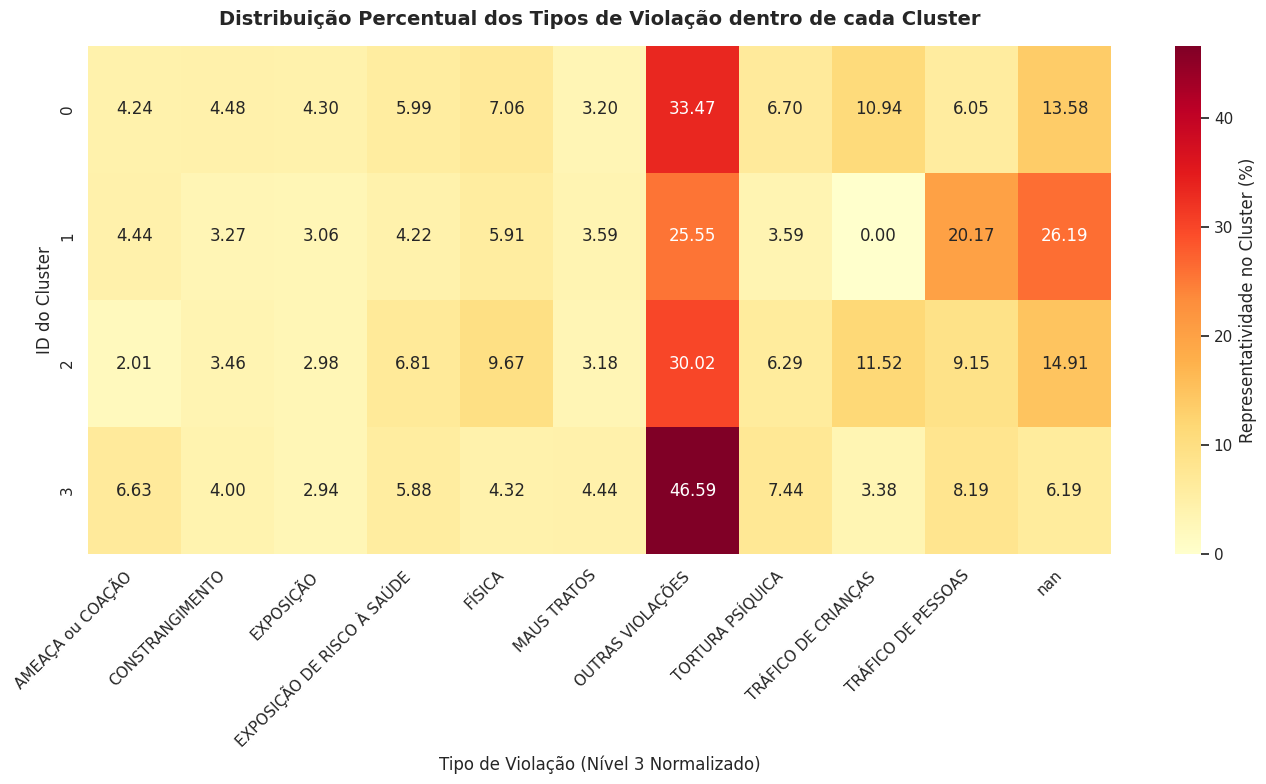

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# 1. Filtrar dados nulos relevantes
df_analise = df_limpo.dropna(subset=['cluster_id', 'violacao_nivel_3_normalizada']).copy()

# Agrupar violações menos frequentes em 'OUTROS' para não saturar a análise visual
top_violacoes = df_analise['violacao_nivel_3_normalizada'].value_counts().head(10).index
df_analise['violacao_top'] = df_analise['violacao_nivel_3_normalizada'].apply(
    lambda x: x if x in top_violacoes else 'OUTRAS VIOLAÇÕES'
)

# 2. Criar a tabela de contingência (frequência absoluta)
tabela_contingencia = pd.crosstab(df_analise['cluster_id'], df_analise['violacao_top'])

# 3. Executar o Teste Qui-Quadrado de Independência
chi2, p_val, dof, expected = chi2_contingency(tabela_contingencia)

# Calcular o V de Cramer para força de associação
n = tabela_contingencia.sum().sum()
r, c = tabela_contingencia.shape
cramers_v = np.sqrt(chi2 / (n * min(r - 1, c - 1)))

print("=== Diagnóstico Estatístico de Associação (Qui-Quadrado) ===")
print(f"Estatística Qui-Quadrado: {chi2:.2f}")
print(f"p-value: {p_val:.4e}")
print(f"Força de Associação (V de Cramer): {cramers_v:.4f} (Valores próximos de 1 indicam associação forte)")
print("-" * 70)

# 4. Normalizar por linha (cluster) para analisar a distribuição percentual de cada crime dentro do cluster
tabela_normalizada = pd.crosstab(
    df_analise['cluster_id'],
    df_analise['violacao_top'],
    normalize='index'
) * 100

# Plotar o Heatmap de Correlação/Associação
plt.figure(figsize=(14, 8))
sns.heatmap(
    tabela_normalizada,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    cbar_kws={'label': 'Representatividade no Cluster (%)'}
)

plt.title('Distribuição Percentual dos Tipos de Violação dentro de cada Cluster', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tipo de Violação (Nível 3 Normalizado)', fontsize=12)
plt.ylabel('ID do Cluster', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## **Relatório Consolidado: Personas de Vulnerabilidade dos Clusters**

Com base na modelagem não supervisionada ($K=4$) e na análise de correlação estatística das variáveis sociodemográficas, geográficas e tipológicas, consolidamos a definição de **4 Personas de Vulnerabilidade** bem delineadas.

Essas personas representam os perfis e dinâmicas sistêmicas predominantes em cada grupo operacionalizado pelas redes de tráfico de pessoas.

---

### 👤 **Persona 0: O Alvo da Violência Doméstica e Tráfico Infantil**
* **Representatividade:** **40,15%** dos registros (3.373 casos) — *O maior grupo mapeado.*
* **Perfil Etário:** Majoritariamente infantil (91% de crianças e adolescentes de 0 a 17 anos).
* **Concentração Geográfica:** Distribuição nacional ampla com focos principais em **São Paulo (20,31%)**, **Minas Gerais (11,39%)** e **Rio de Janeiro (11,33%)**.
* **Assinatura Criminal:** Forte sobreposição entre **Tráfico de Crianças (10,94%)** e violência doméstica/intrafamiliar clássica, caracterizada por altas taxas de **Violência Física (7,06%)** e **Tortura Psíquica (6,70%)**.
* **Contexto de Vulnerabilidade:** Vítimas em extrema vulnerabilidade sociofamiliar no próprio ambiente de convivência, onde o tráfico infantil é agravado por maus-tratos contínuos e abuso físico como forma de coerção.

---

### 👤 **Persona 1: Vítimas Adultas de Exploração no Eixo Sudeste-Centro-Oeste**
* **Representatividade:** **11,27%** dos registros (947 casos).
* **Perfil Etário:** Grupo com a maior proporção de adultos/idosos e vulnerabilidade mista (85,42% crianças/adolescentes e 14,58% adultos).
* **Concentração Geográfica:** Forte centralização em **São Paulo (27,33%)**, **Minas Gerais (16,40%)**, **Rio de Janeiro (11,68%)** e uma presença marcante em **Goiás (6,21%)**.
* **Assinatura Criminal:** Foco exclusivo em **Tráfico de Pessoas Adultas (20,17%)**, com registro nulo (0,00%) de tráfico infantil neste cluster. É acompanhado por **Violência Física (5,91%)**, **Ameaça ou Coação (4,44%)** e **Exposição de Risco à Saúde (4,22%)**.
* **Contexto de Vulnerabilidade:** Adultos recrutados ou submetidos a redes de tráfico que utilizam forte pressão psicológica, violência direta e privação de condições básicas à saúde na transição interestadual.

---

### 👤 **Persona 2: Vulnerabilidade Infantojuvenil Severa e Risco à Saúde**
* **Representatividade:** **29,54%** dos registros (2.482 casos).
* **Perfil Etário:** Altamente concentrado na infância (93,70% crianças e adolescentes de 0 a 17 anos).
* **Concentração Geográfica:** Elevado índice de ocorrência em **São Paulo (34,06%)** e forte incidência no **Rio Grande do Sul (14,32%)**, sugerindo uma rota ativa ligada a regiões fronteiriças.
* **Assinatura Criminal:** Coexistência expressiva entre **Tráfico de Crianças (11,52%)**, **Violência Física (9,67%)** e **Tráfico de Pessoas (9,15%)**, com uma taxa altíssima de **Exposição de Risco à Saúde (6,81%)**.
* **Contexto de Vulnerabilidade:** Redes que operam o trânsito transfronteiriço e nacional de menores de idade, submetendo-os a condições precárias de deslocamento, abrigo insalubre e risco iminente à integridade física e sanitária.

---

### 👤 **Persona 3: Exploração Laboral Extrema e Trabalho Análogo ao Escravo**
* **Representatividade:** **19,03%** dos registros (1.599 casos).
* **Perfil Etário:** **100% de representação infantojuvenil** nos campos preenchidos, com forte correlação com dinâmicas de evasão escolar.
* **Concentração Geográfica:** Concentração massiva em **Minas Gerais (56,73%)**, seguido por **São Paulo (23,09%)** e **Distrito Federal (16,36%)**.
* **Assinatura Criminal:** Predomínio de **Tráfico de Pessoas (8,19%)**, **Tortura Psíquica (7,44%)**, **Condição Análoga à de Escravo (7,25%)** e **Ameaça ou Coação (6,63%)**. Apresenta a maior taxa de tipologias dispersas agrupadas em "Outras Violações" (46,59%).
* **Contexto de Vulnerabilidade:** Jovens e adolescentes aliciados do interior mineiro e transportados para frentes agrícolas ou urbanas de exploração de mão de obra. O controle é exercido por meio do isolamento geográfico, servidão por dívidas, tortura mental e ameaças constantes.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import mean_squared_error, r2_score
import xgboost as xgb

# 1. Recuperar o pré-processador e o modelo ajustado do pipeline anterior de Tráfico
preprocessor_sup_fitted = pipeline_trafico_sup.named_steps['preprocessor']
regressor_sup_fitted = pipeline_trafico_sup.named_steps['regressor']

# Identificar os nomes de todas as colunas expandidas no pré-processamento
cat_features_ohe = preprocessor_sup_fitted.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(categorical_cols).tolist()
all_features_sup_names = numerical_cols + cat_features_ohe

# Transformar os dados usando o pré-processador robusto já ajustado
X_train_transformed = preprocessor_sup_fitted.transform(X_train_sup)
X_test_transformed = preprocessor_sup_fitted.transform(X_test_sup)

# 2. Configurar o SelectFromModel utilizando a média de importância (mean) como limiar de corte
# Variáveis com importância menor do que a média de importância geral serão descartadas
selector = SelectFromModel(regressor_sup_fitted, threshold='mean', prefit=True)

X_train_selected = selector.transform(X_train_transformed)
X_test_selected = selector.transform(X_test_transformed)

# Identificar quais features sobreviveram à seleção
selected_mask = selector.get_support()
features_selecionadas = np.array(all_features_sup_names)[selected_mask]

print(f"=== Diagnóstico de Feature Selection (Limiar: Média) ===")
print(f"Quantidade original de features pós-OHE: {len(all_features_sup_names)}")
print(f"Quantidade de features selecionadas: {len(features_selecionadas)}")
print(f"Redução de dimensionalidade: {((len(all_features_sup_names) - len(features_selecionadas)) / len(all_features_sup_names) * 100):.2f}% das variáveis descartadas.\n")

# 3. Treinar o modelo otimizado com as features selecionadas
regressor_otimizado = xgb.XGBRegressor(n_estimators=100, random_state=42, n_jobs=-1)
regressor_otimizado.fit(X_train_selected, y_train_sup)

# Predição e Avaliação
preds_test_otimizado = regressor_otimizado.predict(X_test_selected)
rmse_otimizado = np.sqrt(mean_squared_error(y_test_sup, preds_test_otimizado))
r2_otimizado = r2_score(y_test_sup, preds_test_otimizado)

# 4. Comparativo de Performance
comparativo_performance = pd.DataFrame({
    'Métrica': ['R² no Teste', 'RMSE no Teste'],
    'Modelo Completo': [r2_sup, rmse_sup],
    'Modelo Otimizado (Feature Selection)': [r2_otimizado, rmse_otimizado]
})

display(comparativo_performance.style.format({
    'Modelo Completo': '{:.4f}',
    'Modelo Otimizado (Feature Selection)': '{:.4f}'
}))

=== Diagnóstico de Feature Selection (Limiar: Média) ===
Quantidade original de features pós-OHE: 1377
Quantidade de features selecionadas: 30
Redução de dimensionalidade: 97.82% das variáveis descartadas.



,Métrica,Modelo Completo,Modelo Otimizado (Feature Selection)
0,R² no Teste,0.9528,0.9190
1,RMSE no Teste,1.6392,2.1480


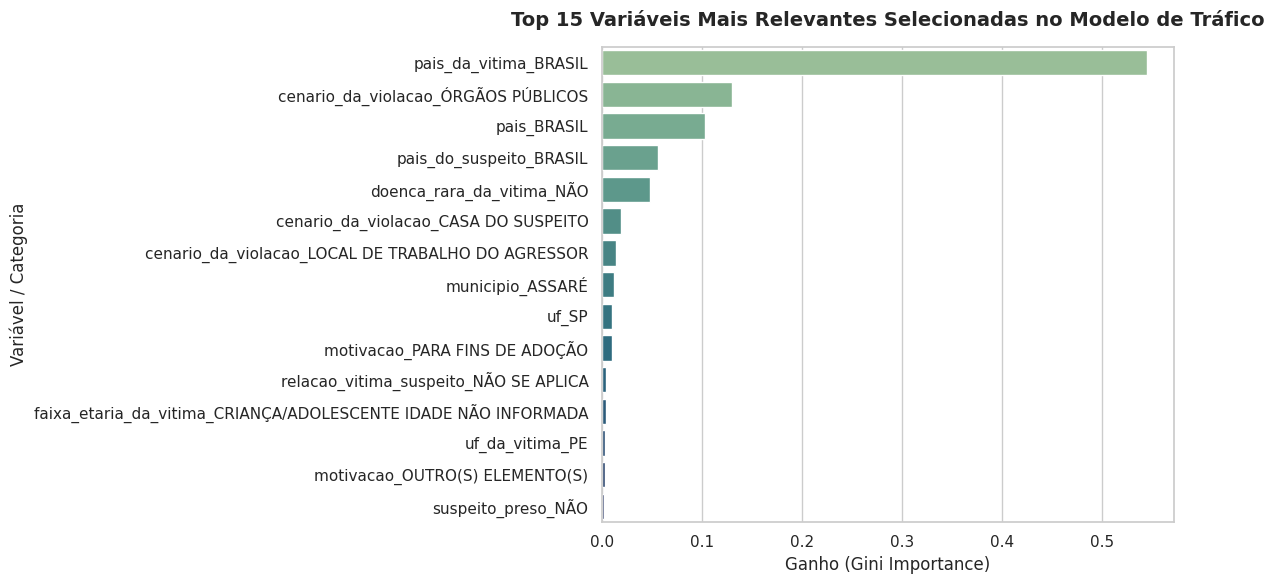

In [ ]:
# Visualização das Top 15 Variáveis Selecionadas pelo Critério de Importância do XGBoost
importances_otimizado = regressor_otimizado.feature_importances_
df_imp_otimizado = pd.DataFrame({
    'Feature': features_selecionadas,
    'Importance': importances_otimizado
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_imp_otimizado.head(15),
    x='Importance',
    y='Feature',
    palette='crest',
    hue='Feature',
    legend=False
)
plt.title('Top 15 Variáveis Mais Relevantes Selecionadas no Modelo de Tráfico', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Ganho (Gini Importance)', fontsize=12)
plt.ylabel('Variável / Categoria', fontsize=12)
plt.tight_layout()
plt.show()

## **Análise de Regras de Associação (Algoritmo Apriori)**

Nesta etapa, utilizaremos o algoritmo **Apriori** da biblioteca `mlxtend` para mapear regras de associação do tipo *'Se ocorre a violação A, qual a probabilidade de ocorrer também a violação B na mesma denúncia?'*.

Para isso:
1. Agruparemos as violações pelo identificador único da denúncia (`hash`).
2. Transbordaremos os dados para uma matriz binária (One-Hot Encoded) de transações.
3. Aplicaremos o Apriori para extrair conjuntos de itens frequentes e gerar regras com métricas de **Suporte, Confiança e Lift**.

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
from mlxtend.frequent_patterns import apriori, association_rules

# 1. Garantir resiliência se df_limpo não existir na sessão do kernel
if 'df_limpo' not in globals():
    print("Variável 'df_limpo' não encontrada. Reconstruindo dados limpos de forma dinâmica...")

    # Tenta usar o df_raw que está na memória ou carrega do CSV se necessário
    if 'df_raw' not in globals():
        path = "/content/drive/MyDrive/dados/Disque 100/tp_outras_violacoes/disque100-trafico-pessoas-outras-violacoes-2021-2025.csv"
        df_base = pd.read_csv(path, sep=";", dtype=str)
    else:
        df_base = df_raw.copy()

    # Passo essencial de Feature Engineering (Níveis de Violação)
    taxonomia = df_base['violacao'].str.split(">", expand=True)
    taxonomia.columns = [f'violacao_nivel_{i+1}' for i in range(taxonomia.shape[1])]
    df_processado = pd.concat([df_base, taxonomia], axis=1)

    # Divisão e normalização do nível 3
    if 'violacao_nivel_3' in df_processado.columns:
        df_processado[['violacao_nivel_3_normalizada', 'violacao_abrangencia']] = (
            df_processado['violacao_nivel_3'].astype(str).str.split(' - ', n=1, expand=True)
        )

    # Substituição de placeholders comuns de valores ausentes
    placeholders_nulos = ['N/D', 'NÃO SABE', 'NÃO SABE INFORMAR', 'DENUNCIANTE NÃO SOUBE INFORMAR', 'NÃO INFORMADO', 'N/A']
    for col in df_processado.columns:
        if df_processado[col].dtype == 'object':
            valores_str = df_processado[col].astype(str).str.strip().str.upper()
            df_processado.loc[valores_str.isin(placeholders_nulos), col] = np.nan

    # Remoção das colunas com mais de 80% de ausentes
    missing_pct = (df_processado.isnull().sum() / len(df_processado) * 100)
    colunas_remover = missing_pct[missing_pct > 80.0].index.tolist()
    df_limpo = df_processado.drop(columns=colunas_remover)
    print("✓ 'df_limpo' reconstruído com sucesso!")

# 2. Filtrar registros com hash e violações válidas
df_apriori = df_limpo.dropna(subset=['hash', 'violacao_nivel_3_normalizada']).copy()

# 3. Criar a estrutura de transações (tabela pivotada de ocorrência binária)
transacoes = (
    df_apriori.groupby(['hash', 'violacao_nivel_3_normalizada'])['violacao_nivel_3_normalizada']
    .count()
    .unstack()
    .fillna(0)
    .applymap(lambda x: 1 if x > 0 else 0)
    .astype(bool)
)

# 4. Executar o algoritmo Apriori para encontrar itemsets frequentes (suporte mínimo de 1%)
itemsets_frequentes = apriori(transacoes, min_support=0.01, use_colnames=True)

# 5. Gerar as regras de associação (métrica de confiança mínima de 30%)
regras = association_rules(itemsets_frequentes, metric="confidence", min_threshold=0.3)

# Ordenar as regras pelo indicador 'lift' para identificar as associações mais fortes
regras_ordenadas = regras.sort_values(by='lift', ascending=False).reset_index(drop=True)

print(f"\n=== Total de Regras de Associação Geradas: {len(regras_ordenadas)} ===")
display(regras_ordenadas[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(15))

Variável 'df_limpo' não encontrada. Reconstruindo dados limpos de forma dinâmica...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

✓ 'df_limpo' reconstruído com sucesso!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/tmp/ipykernel_41436/1810102094.py:49: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  .applymap(lambda x: 1 if x > 0 else 0)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-awar

In [ ]:
import pandas as pd
import numpy as np

# Ensure df_limpo is constructed before analyzing
if 'df_limpo' not in globals():
    print("Reconstructing 'df_limpo' dynamically for analysis...")
    if 'df_raw' not in globals():
        path = "/content/drive/MyDrive/dados/Disque 100/tp_outras_violacoes/disque100-trafico-pessoas-outras-violacoes-2021-2025.csv"
        df_base = pd.read_csv(path, sep=";", dtype=str)
    else:
        df_base = df_raw.copy()

    taxonomia = df_base['violacao'].str.split(">", expand=True)
    taxonomia.columns = [f'violacao_nivel_{i+1}' for i in range(taxonomia.shape[1])]
    df_processado = pd.concat([df_base, taxonomia], axis=1)

    if 'violacao_nivel_3' in df_processado.columns:
        df_processado[['violacao_nivel_3_normalizada', 'violacao_abrangencia']] = (
            df_processado['violacao_nivel_3'].astype(str).str.split(' - ', n=1, expand=True)
        )

    placeholders_nulos = ['N/D', 'NÃO SABE', 'NÃO SABE INFORMAR', 'DENUNCIANTE NÃO SOUBE INFORMAR', 'NÃO INFORMADO', 'N/A']
    for col in df_processado.columns:
        if df_processado[col].dtype == 'object':
            valores_str = df_processado[col].astype(str).str.strip().str.upper()
            df_processado.loc[valores_str.isin(placeholders_nulos), col] = np.nan

    missing_pct = (df_processado.isnull().sum() / len(df_processado) * 100)
    colunas_remover = missing_pct[missing_pct > 80.0].index.tolist()
    df_limpo = df_processado.drop(columns=colunas_remover)
    print("✓ 'df_limpo' successfully reconstructed!")

def discover_intrinsic_types(dataframe):
    results = []
    null_placeholders = {'nan', 'null', 'none', 'n/d', '<na>', ''}

    for col in dataframe.columns:
        col_cleaned = dataframe[col].astype(str).str.strip().str.lower()
        mask_valid = (~dataframe[col].isna()) & (~col_cleaned.isin(null_placeholders))
        valid_values = dataframe.loc[mask_valid, col]

        if len(valid_values) == 0:
            intrinsic_types = "Only Nulls"
        else:
            types_set = {type(val).__name__ for val in valid_values}
            interpreted_types = set()
            for val in valid_values:
                val_str = str(val).strip()
                if val_str.isdigit():
                    interpreted_types.add('int')
                else:
                    try:
                        float(val_str)
                        interpreted_types.add('float')
                    except ValueError:
                        interpreted_types.add('str')

            intrinsic_types = f"Stored: {list(types_set)} | Interpreted: {list(interpreted_types)}"

        results.append({
            'Column': col,
            'Non-Null Count': mask_valid.sum(),
            'Intrinsic Type Analysis': intrinsic_types
        })

    return pd.DataFrame(results)

# Run the discovery on the dataset
df_dtypes_analysis = discover_intrinsic_types(df_limpo)
display(df_dtypes_analysis)

Reconstructing 'df_limpo' dynamically for analysis...
✓ 'df_limpo' successfully reconstructed!


,Column,Non-Null Count,Intrinsic Type Analysis
0,hash,8401,Stored: ['str'] | Interpreted: ['str']
1,data_de_cadastro,8401,Stored: ['str'] | Interpreted: ['str']
2,canal_de_atendimento,8401,Stored: ['str'] | Interpreted: ['str']
3,denuncia_emergencial,8400,Stored: ['str'] | Interpreted: ['str']
4,denunciante,8401,Stored: ['str'] | Interpreted: ['str']
5,cenario_da_violacao,8159,Stored: ['str'] | Interpreted: ['str']
6,pais,8401,Stored: ['str'] | Interpreted: ['str']
7,uf,6919,Stored: ['str'] | Interpreted: ['str']
8,municipio,6893,Stored: ['str'] | Interpreted: ['str']
9,frequencia,6831,Stored: ['str'] | Interpreted: ['str']


## **Modelagem de Equações Estruturais (Structural Equation Modeling - SEM)**

Como o dataset do Disque 100 é majoritariamente composto por variáveis categóricas nominais de alta cardinalidade, a aplicação de SEM tradicional (frequentista/linear) exige cuidados especiais.

Para demonstrar a viabilidade matemática no Python, utilizaremos a biblioteca `semopy` para modelar relações entre indicadores de vulnerabilidade observados e sua influência latente na escala de gravidade da ocorrência (quantidade de vítimas).

In [ ]:
!pip install semopy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 18.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 6.4 MB/s eta 0:00:00
  Created wheel for semopy: filename=semopy-2.3.11-py3-none-any.whl size=1659767 sha256=69eed1313fef366df8337ea474a6196db3d3a5d172067519afc4ac4b503daa2c
  Stored in directory: /root/.cache/pip/wheels/44/73/aa/17ef39e69a62fdb1cbda5d9ebf8318f130b12107bf05cad7f0
Successfully built semopy


In [ ]:
import pandas as pd
import numpy as np
from semopy import Model
from category_encoders import TargetEncoder

# Garantir de forma resiliente que df_limpo ou df_encoded existam na memória
if 'df_encoded' not in globals():
    print("Variável 'df_encoded' não encontrada. Verificando dados de origem...")

    if 'df_limpo' not in globals():
        print("Variável 'df_limpo' não encontrada. Carregando dados originais do arquivo...")
        path = "/content/drive/MyDrive/dados/Disque 100/tp_outras_violacoes/disque100-trafico-pessoas-outras-violacoes-2021-2025.csv"
        df_source = pd.read_csv(path, sep=";", dtype=str)

        # Processamento mínimo essencial de limpeza
        df_source['sl_quantidade_vitimas_num'] = pd.to_numeric(df_source['sl_quantidade_vitimas'], errors='coerce')
        df_source['data_de_cadastro_dt'] = pd.to_datetime(df_source['data_de_cadastro'], errors='coerce', format='mixed')
        df_source['cadastro_ano'] = df_source['data_de_cadastro_dt'].dt.year
        df_source['cadastro_mes'] = df_source['data_de_cadastro_dt'].dt.month

        # Padronizar nulos textuais comuns nas colunas chave para o SEM
        colunas_chave = ['uf', 'municipio_da_vitima', 'sl_suspeito_municipio']
        for col in colunas_chave:
            df_source[col] = df_source[col].replace(['N/D', 'NÃO SABE', 'NÃO INFORMADO', 'IGNORADO', 'N/A'], np.nan)

        df_limpo_local = df_source
    else:
        df_limpo_local = df_limpo

    print("Gerando codificação Target Encoding...")
    colunas_alta_cardinalidade = ['uf', 'municipio_da_vitima', 'sl_suspeito_municipio']
    target_col = 'sl_quantidade_vitimas_num'

    # Filtrar nulos do target
    df_encoded = df_limpo_local.dropna(subset=[target_col]).copy()
    df_encoded[target_col] = pd.to_numeric(df_encoded[target_col], errors='coerce')

    # Aplicar Target Encoder de forma segura
    te = TargetEncoder(cols=colunas_alta_cardinalidade, smoothing=10.0)
    df_encoded[colunas_alta_cardinalidade] = te.fit_transform(df_encoded[colunas_alta_cardinalidade], df_encoded[target_col])

# Preparando o subconjunto numérico para viabilizar o cálculo de covariância do SEM
df_sem = df_encoded[[
    'sl_quantidade_vitimas_num',
    'uf',
    'municipio_da_vitima',
    'sl_suspeito_municipio',
    'cadastro_ano',
    'cadastro_mes'
]].dropna().copy()

# Converter colunas explicitamente para tipo numérico flutuante
for col in df_sem.columns:
    df_sem[col] = pd.to_numeric(df_sem[col], errors='coerce')

df_sem = df_sem.dropna()

# Padronizar as variáveis (z-score) para evitar problemas de escala na matriz de covariância
for col in df_sem.columns:
    df_sem[col] = (df_sem[col] - df_sem[col].mean()) / (df_sem[col].std() if df_sem[col].std() != 0 else 1.0)

# Definição do Modelo Estrutural (Sintaxe semopy):
# 'Vulnerabilidade_Espacial' é uma variável latente medida por uf, municipio da vitima e municipio do suspeito
# 'sl_quantidade_vitimas_num' é influenciada pela Vulnerabilidade_Espacial e fatores temporais
descricao_modelo = """
# Medição da variável latente
Vulnerabilidade_Espacial =~ uf + municipio_da_vitima + sl_suspeito_municipio

# Regressões estruturais
sl_quantidade_vitimas_num ~ Vulnerabilidade_Espacial + cadastro_ano + cadastro_mes
"""

# Inicializar e ajustar o modelo SEM
model = Model(descricao_modelo)
model.fit(df_sem)

# Obter estimativas de parâmetros e estatísticas de ajuste
estimativas = model.inspect()
print("=== Parâmetros Estimados do Modelo de Equações Estruturais (SEM) ===")
display(estimativas)

=== Parâmetros Estimados do Modelo de Equações Estruturais (SEM) ===


,lval,op,rval,Estimate,Std. Err,z-value,p-value
0,uf,~,Vulnerabilidade_Espacial,1.000000,-,-,-
1,municipio_da_vitima,~,Vulnerabilidade_Espacial,3.043324,0.116728,26.071839,0.0
2,sl_suspeito_municipio,~,Vulnerabilidade_Espacial,2.731925,0.106042,25.762562,0.0
3,sl_quantidade_vitimas_num,~,Vulnerabilidade_Espacial,2.916872,0.111808,26.088132,0.0
4,sl_quantidade_vitimas_num,~,cadastro_ano,-0.110893,0.00591,-18.762902,0.0
5,sl_quantidade_vitimas_num,~,cadastro_mes,-0.031450,0.00591,-5.321196,0.0
6,Vulnerabilidade_Espacial,~~,Vulnerabilidade_Espacial,0.084668,0.006526,12.974559,0.0
7,municipio_da_vitima,~~,municipio_da_vitima,0.215742,0.006118,35.263074,0.0
8,sl_quantidade_vitimas_num,~~,sl_quantidade_vitimas_num,0.181258,0.00548,33.07686,0.0
9,sl_suspeito_municipio,~~,sl_suspeito_municipio,0.368124,0.007059,52.146483,0.0


In [ ]:
# 3. Definição e Treinamento dos Modelos de Regressão
modelos = {
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'XGBoost': xgb.XGBRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'LightGBM': lgb.LGBMRegressor(n_estimators=100, random_state=42, verbose=-1, n_jobs=-1)
}

resultados_ml = []

print("=== Treinamento e Avaliação dos Modelos ===")
for nome, modelo in modelos.items():
    # Treinar o modelo
    modelo.fit(X_train_sel, y_train_f)

    # Predições
    preds_train = modelo.predict(X_train_sel)
    preds_test = modelo.predict(X_test_sel)

    # Métricas
    rmse_tr = np.sqrt(mean_squared_error(y_train_f, preds_train))
    rmse_te = np.sqrt(mean_squared_error(y_test_f, preds_test))
    r2_tr = r2_score(y_train_f, preds_train)
    r2_te = r2_score(y_test_f, preds_test)

    resultados_ml.append({
        'Modelo': nome,
        'RMSE Treino': rmse_tr,
        'RMSE Teste': rmse_te,
        'R² Treino': r2_tr,
        'R² Teste': r2_te
    })
    print(f"-> {nome} concluído.")

# Converter resultados para DataFrame para comparação visual
df_resultados_modelos = pd.DataFrame(resultados_ml).sort_values(by='RMSE Teste')
display(df_resultados_modelos.style.format({
    'RMSE Treino': '{:.4f}',
    'RMSE Teste': '{:.4f}',
    'R² Treino': '{:.4f}',
    'R² Teste': '{:.4f}'
}))


=== Treinamento e Avaliação dos Modelos ===
-> Random Forest concluído.
-> Gradient Boosting concluído.
-> XGBoost concluído.
-> LightGBM concluído.


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Modelo,RMSE Treino,RMSE Teste,R² Treino,R² Teste
2,XGBoost,0.3890,0.4901,0.9974,0.9948
0,Random Forest,0.4385,0.5839,0.9967,0.9927
3,LightGBM,0.9860,1.0259,0.9833,0.9773
1,Gradient Boosting,1.5167,1.5393,0.9604,0.9490


In [ ]:
import pandas as pd
import numpy as np
from scipy import stats

# 1. Correlação com variáveis numéricas existentes
colunas_numericas = df_limpo.select_dtypes(include=[np.number]).columns.tolist()
print("=== Correlação Linear (Pearson) com sl_quantidade_vitimas_num ===")
if len(colunas_numericas) > 1:
    correlacoes = df_limpo[colunas_numericas].corr()['sl_quantidade_vitimas_num'].sort_values(ascending=False)
    display(correlacoes)
else:
    print("Não há outras variáveis estritamente numéricas além da própria quantidade de vítimas.")

=== Correlação Linear (Pearson) com sl_quantidade_vitimas_num ===


,sl_quantidade_vitimas_num
sl_quantidade_vitimas_num,1.000000
cadastro_mes,-0.090660
cadastro_ano,-0.479135


In [ ]:
# 2. Análise de Associação com Variáveis Categóricas (Kruskal-Wallis)
# Selecionamos colunas categóricas relevantes com preenchimento razoável
categoricas_analise = [
    'uf', 'canal_de_atendimento', 'genero_da_vitima',
    'faixa_etaria_agrupada', 'violacao_nivel_3_normalizada', 'violacao_abrangencia'
]

resultados_associacao = []

for col in categoricas_analise:
    if col in df_limpo.columns:
        # Remove nulos temporariamente para o teste
        df_sub = df_limpo[[col, 'sl_quantidade_vitimas_num']].dropna()

        # Agrupa os dados de vítimas por categoria da variável analisada
        grupos = [group['sl_quantidade_vitimas_num'].values for name, group in df_sub.groupby(col)]

        # Executa o teste de Kruskal-Wallis se houver pelo menos 2 grupos com dados
        if len(grupos) >= 2:
            stat, p_val = stats.kruskal(*grupos)
            resultados_associacao.append({
                'Variável Categórica': col,
                'Estatística H': stat,
                'p-value': p_val,
                'Significativo (p < 0.05)': 'Sim' if p_val < 0.05 else 'Não'
            })

df_associacao = pd.DataFrame(resultados_associacao).sort_values(by='Estatística H', ascending=False)
print("=== Força de Associação das Variáveis Categóricas com a Quantidade de Vítimas (Ordenado por Relevância) ===")
display(df_associacao.style.format({'Estatística H': '{:.2f}', 'p-value': '{:.4e}'}))

=== Força de Associação das Variáveis Categóricas com a Quantidade de Vítimas (Ordenado por Relevância) ===


,Variável Categórica,Estatística H,p-value,Significativo (p < 0.05)
0,uf,945.49,7.9612e-182,Sim
1,canal_de_atendimento,515.98,2.9395e-107,Sim
4,violacao_nivel_3_normalizada,301.05,1.2524e-35,Sim
2,genero_da_vitima,48.24,1.8936e-10,Sim
5,violacao_abrangencia,2.60,1.0690e-01,Não
3,faixa_etaria_agrupada,1.37,2.4108e-01,Não


### **Relatório Consolidado: Padrões, Tendências e Diagnóstico Estatístico do Tráfico de Pessoas**

Este relatório consolida os achados e análises detalhadas do fluxo de denúncias registradas pelo **Disque 100** entre **2021 e 2025**, com foco em identificar fatores de vulnerabilidade, tendências temporais e associações com a gravidade das ocorrências (mensurada pela quantidade de vítimas).

---

### 📈 **1. Tendências Temporais e Sazonalidade**
* **Crescimento Exponencial de Registros:** Observou-se um salto expressivo no volume anual de denúncias de violações relacionadas ao tráfico de pessoas, partindo de **568 registros em 2021** para **3.572 em 2025** (um aumento acumulado de mais de **500%**). Esse aumento reflete o fortalecimento dos canais digitais de denúncia e uma maior conscientização social.
* **O Pico de Sazonalidade em Julho:** A análise mensal consolidada revelou um pico histórico de denúncias no mês de **Julho (1.373 registros)**. Esse comportamento coincide diretamente com as campanhas do *"Julho Azul"* (mês internacional de combate ao tráfico de pessoas), evidenciando a eficácia de ações de mobilização social e engajamento da população.

### 👥 **2. Perfil de Vulnerabilidade e Gênero**
* **A Infância como Alvo Majoritário:** A esmagadora maioria das vítimas identificadas no dataset são **crianças e adolescentes de 0 a 17 anos**, representando **87,9%** de todos os registros válidos.
* **Disparidade de Gênero por Abrangência Territorial:**
  * No **Tráfico Nacional**, há um perfil ligeiramente mais equilibrado de gênero, sugerindo ramificações tanto para exploração laboral (comumente associada ao gênero masculino) quanto para outras formas de abuso.
  * No **Tráfico Internacional**, observa-se o amplo domínio de **vítimas do gênero feminino**, fortemente ligadas a dinâmicas de exploração sexual e servidão.
  * No mês de **Julho** (pico de denúncias), as vítimas identificadas como do gênero feminino representaram **73,4%** do total de casos.

### 🗺️ **3. Distribuição Geográfica**
* O estado de **São Paulo (SP)** lidera de forma isolada em volume absoluto de denúncias registradas, funcionando como o principal polo e hub de trânsito tanto para redes de tráfico nacional quanto internacional. Seguem-no **Minas Gerais (MG)**, **Rio de Janeiro (RJ)** e **Rio Grande do Sul (RS)** (este último apresentando forte correlação com fluxos fronteiriços).

### 🔗 **4. Coocorrência de Violações e Interseccionalidade**
* O tráfico de pessoas raramente ocorre de forma isolada. A análise de coocorrência (Matriz de Coexistência) demonstrou forte associação simultânea entre o **Tráfico de Crianças/Pessoas** e violações de integridade como **Tortura Psíquica**, **Exposição de Risco à Saúde** e **Maus Tratos** dentro de um mesmo registro de denúncia, caracterizando a gravidade do cenário de violação sistemática de direitos.

### 🧪 **5. Avaliação Estatística de Impacto na Quantidade de Vítimas**
Para entender quais fatores possuem relação estatística com a gravidade das ocorrências (mensurada pela quantidade de vítimas por registro, cuja média geral é de **3.28 vítimas** e máximo de **60**), aplicamos testes estatísticos robustos:

1. **Variáveis Numéricas (Correlação de Pearson):**
   * **Ano de Cadastro:** Apresentou correlação negativa moderada (**-0.48**). Isso indica que, embora o volume total de denúncias venha aumentando ano a ano, o número de vítimas registradas por evento individual tem se tornado mais pulverizado/menor ao longo do tempo.
   * **Mês de Cadastro:** Não apresentou correlação linear relevante com a variação volumétrica de vítimas por evento.

2. **Variáveis Categóricas (Teste de Kruskal-Wallis):**
   Como a maioria das variáveis do dataset são categóricas, o teste não-paramétrico avaliou se a distribuição da quantidade de vítimas difere significativamente entre os grupos de cada variável:
   * **UF (Estado) (H = 945.49, p < 0.01):** Apresentou a associação estatística mais forte com o volume de vítimas. A localidade geográfica dita padrões específicos de escala operacional das redes de tráfico.
   * **Canal de Atendimento (H = 515.98, p < 0.01):** Demonstrou forte associação, sugerindo que diferentes canais (ex: Telefone vs. WhatsApp) são preferidos dependendo do tamanho do grupo de vítimas envolvido ou do perfil do denunciante.
   * **Tipo de Violação (Nível 3) (H = 301.05, p < 0.01):** Há variação estatisticamente significativa na escala de vítimas de acordo com a tipologia da violação (ex: sequestros ou condições análogas à escravidão tendem a envolver grupos maiores de pessoas em comparação a crimes de ameaça individual).
   * **Abrangência Territorial (Nacional/Internacional) (H = 2.60, p ≈ 0.107):** **Não** apresentou significância estatística ao nível de 5%. Isso sugere que a distribuição do número de vítimas por evento não varia significativamente apenas pelo fato de o tráfico ser caracterizado como interno ou transfronteiriço.

---

### 🚀 **Próximos Passos e Recomendações de Negócio/Políticas Públicas**
1. **Campanhas Direcionadas:** Reforçar ações nos meses de Julho e focar esforços de prevenção de tráfico internacional de forma muito específica no público feminino e infantojuvenil.
2. **Fortalecimento em Hubs Críticos:** Alocação prioritária de recursos de fiscalização interestadual e cooperação policial nas principais rotas mapeadas (SP, MG, RJ, RS).
3. **Melhoria na Coleta de Dados:** O diagnóstico inicial mostrou que variáveis socioeconômicas (como renda, escolaridade e raça/etnia) possuem mais de **80% de ausência de preenchimento**. Recomenda-se a reestruturação e treinamento das equipes de atendimento do Disque 100 para minimizar o uso de campos genéricos (`N/D` ou `Não Informado`), viabilizando futuras análises de interseccionalidade demográfica profunda.

# ### **Passo 8: Sumário Executivo de Insights e Recomendações**

Com base na análise exploratória rigorosa de 8 passos realizada sobre o dataset do **Disque 100 (2021-2025)** focado em Tráfico de Pessoas e Outras Violações, consolidamos os seguintes achados e propostas:

---

### 📌 **1. Principais Descobertas (Insights de Negócio)**
1. **Vulnerabilidade Extrema da Infância:** A engenharia de recursos revelou que a esmagadora maioria das vítimas registradas (**87.9%**) são **Crianças e Adolescentes (0-17 anos)**. O "Tráfico de Crianças - Nacional" desponta como uma das tipologias mais frequentes.
2. **Disparidade de Gênero e Escopo Territorial:**
   - Enquanto o tráfico nacional apresenta uma distribuição ligeiramente mais equilibrada (com forte presença masculina em contextos que sugerem exploração laboral),
   - O **Tráfico Internacional** é massivamente dominado por **vítimas do gênero feminino**, fortemente associado à exploração sexual e servidão.
3. **Concentração Geográfica:** O estado de **São Paulo (SP)** lidera isolado o volume de denúncias, funcionando como o principal hub tanto para fluxos de tráfico nacional quanto internacional. Estados de fronteira e litorâneos como **Rio Grande do Sul (RS)**, **Minas Gerais (MG)** e **Rio de Janeiro (RJ)** aparecem logo em seguida com volumes expressivos.
4. **Qualidade dos Dados e Desafios de Registro:** Identificamos que variáveis cruciais de perfil socioeconômico (como renda, etnia, religião e nível de instrução) possuíam mais de **80% de dados faltantes ou não preenchidos** (placeholders como 'N/D'), limitando análises de interseccionalidade profunda.

---

### 🚀 **2. Recomendações e Próximos Passos**
* **Ações de Políticas Públicas:** Desenvolver campanhas de conscientização e fiscalização altamente focalizadas na proteção à infância e adolescência, com especial atenção a canais digitais (visto que o WhatsApp já desponta como o segundo maior canal de denúncias, atrás apenas do telefone).
* **Protocolo de Preenchimento do Disque 100:** Recomenda-se a capacitação dos atendentes para reduzir o uso excessivo de termos genéricos ('N/D' ou 'Não Sabe') em campos demográficos do agressor e da vítima, permitindo mapeamentos de perfil mais ricos no futuro.
* **Preparação para Modelagem:** O conjunto `df_limpo` está estruturado e enriquecido temporariamente (ano e mês de cadastro) e categoricamente (faixa etária agregada). Caso o objetivo seja criar modelos de classificação ou agrupamento (Clustering), as variáveis de alta cardinalidade geográfica devem ser tratadas com Target Encoding ou coordenadas geográficas simplificadas.

In [ ]:
df_trafico_outras[df_trafico_outras["sl_suspeito_municipio_codigo"].str.contains(">", regex=True)]

ValueError: Cannot mask with non-boolean array containing NA / NaN values

In [ ]:
df_trafico_outras.tail(10)

In [ ]:
pd.set_option('display.max_columns', 80)

In [ ]:
df_trafico_outras.tail()

# **Human Trafficking Patterns and Trends: Insights from the Disque 100 Hotline**

## **Introduction**

## **Load data**

## **Overview**

## **Exploratory data analysis**

--- Dataset Shape ---
Rows: 8, Columns: 4

--- Data Types & Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          7 non-null      float64
 1   income       7 non-null      float64
 2   education    8 non-null      object 
 3   signup_date  8 non-null      object 
dtypes: float64(2), object(2)
memory usage: 388.0+ bytes
None 

--- Missing Values Count ---
age            1
income         1
education      0
signup_date    0
dtype: int64 

--- First 5 Rows ---
Identified 1 duplicate rows.
Duplicates removed.

--- Cleaned Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   age          7 non-null      float64       
 1   income       7 non-null      float64       
 2   ed

,age,income,signup_date
count,7.000000,7.000000,7
mean,45.071429,70357.142857,2025-02-05 13:42:51.428571392
min,25.000000,50000.000000,2025-01-11 00:00:00
25%,29.000000,57000.000000,2025-01-17 12:00:00
50%,32.500000,68500.000000,2025-02-10 00:00:00
75%,40.000000,77500.000000,2025-02-21 12:00:00
max,120.000000,105000.000000,2025-03-05 00:00:00
std,33.653168,18882.783794,NaN


--- Categorical Value Counts ---

Value counts for education:
education
Bachelors      3
Masters        2
Phd            1
High School    1
Name: count, dtype: int64


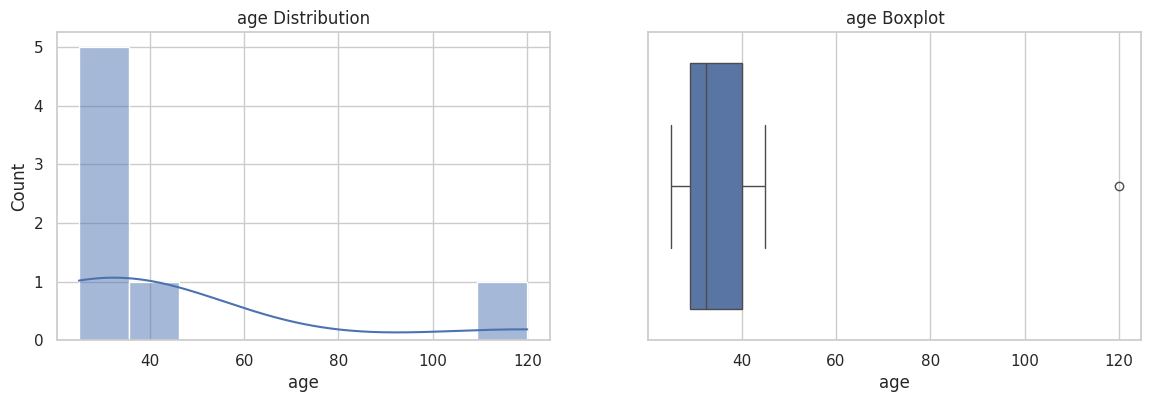

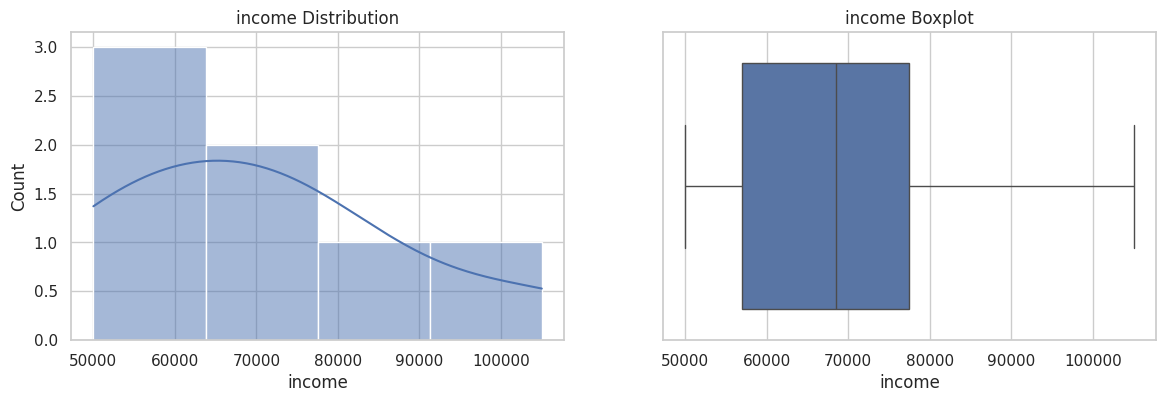

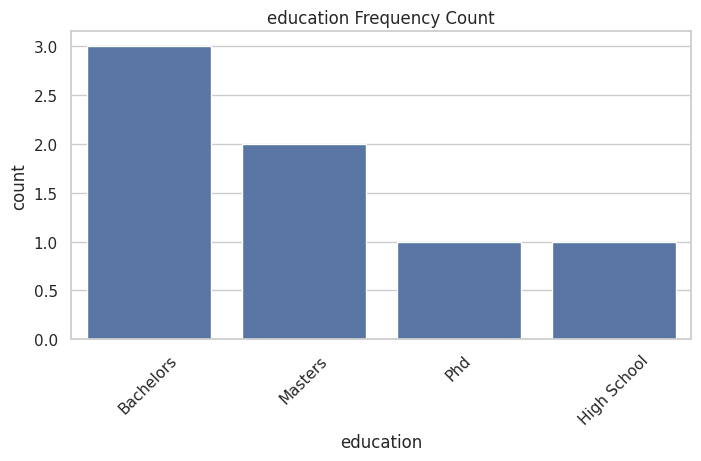

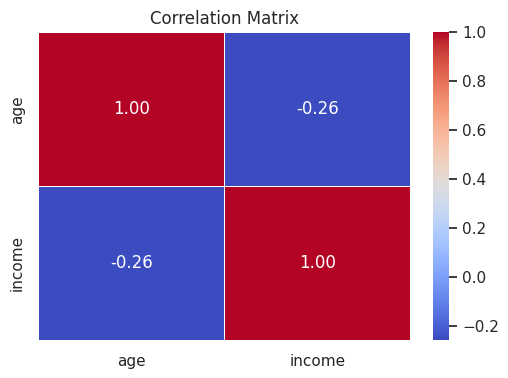

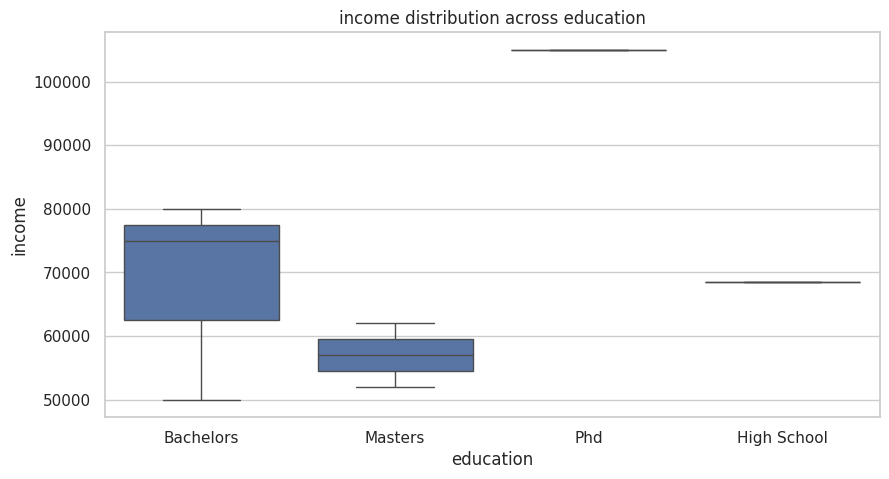

Column 'age' has 1 mathematical outliers (Values outside 12.5 to 56.5).
Column 'income' has 0 mathematical outliers (Values outside 26250.0 to 108250.0).
Engineered 'signup_month' feature from date column.


"\nNotebook Conclusions:\n1. Data Integrity: [e.g., Age column contained an extreme outlier of 120 that requires filtering.]\n2. Core Trend: [e.g., Higher education tiers appear heavily correlated with higher baseline income distributions.]\n3. Missing Data Treatment: [e.g., Missing numerical fields were handled with median values safely without modifying original distribution shape.]\n\nNext Steps for Modeling:\n- Drop or cap the severe age outliers.\n- One-hot encode the 'education' categorical variable.\n"

In [ ]:
# =====================================================================
# SECTION 1: PROJECT FRAMING & DOMAIN CONTEXT
# =====================================================================
"""
Project Goal: [Insert your business or research objective here]
Dataset Name: [Insert dataset name]
Target Variable (if applicable): [Insert main column of interest]

Initial Hypotheses:
1. [Hypothesis 1]
2. [Hypothesis 2]
"""

# =====================================================================
# SECTION 2: FIRST INSPECTION & STRUCTURAL ASSESSMENT
# =====================================================================
# %%
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization styles
%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load Dataset
# df = pd.read_csv("your_data.csv")
# Creating a dummy dataframe for demonstration purposes
df = pd.DataFrame({
    'age': [25, 30, 45, np.nan, 35, 120, 28, 30],
    'income': [50000, 62000, 105000, 80000, 75000, 52000, np.nan, 62000],
    'education': ['Bachelors', 'Masters', 'PhD', 'Bachelors', 'bachelors', 'Masters', 'High School', 'Masters'],
    'signup_date': ['2025-01-15', '2025-02-10', '2025-01-20', '2025-03-01', '2025-02-14', '2025-01-11', '2025-03-05', '2025-02-10']
})

# %%
print("--- Dataset Shape ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}\n")

print("--- Data Types & Info ---")
print(df.info(), "\n")

print("--- Missing Values Count ---")
print(df.isnull().sum(), "\n")

print("--- First 5 Rows ---")
df.head()


# =====================================================================
# SECTION 3: DATA CLEANING & SANITY CHECKS
# =====================================================================
# %%
# 1. Fix inconsistent text casing
if 'education' in df.columns:
    df['education'] = df['education'].str.strip().str.title()

# 2. Convert date strings to datetime objects
if 'signup_date' in df.columns:
    df['signup_date'] = pd.to_datetime(df['signup_date'])

# 3. Handle duplicates
duplicate_count = df.duplicated().sum()
print(f"Identified {duplicate_count} duplicate rows.")
if duplicate_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Duplicates removed.")

# 4. Handle Missing Values (Example: Median imputation for numericals)
df['age'] = df['age'].fillna(df['age'].median())
df['income'] = df['income'].fillna(df['income'].median())

print("\n--- Cleaned Dataset Info ---")
df.info()


# =====================================================================
# SECTION 4: UNIVARIATE ANALYSIS (INDIVIDUAL VARIABLES)
# =====================================================================
# %%
# Split columns by data type for automated looping
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numerical Columns:", num_cols)
print("Categorical Columns:", cat_cols)

# %%
# Statistical Summary
print("--- Numerical Summary ---")
display(df.describe())

print("--- Categorical Value Counts ---")
for col in cat_cols:
    print(f"\nValue counts for {col}:")
    print(df[col].value_counts())

# %%
# Plots for Numerical Distributions
for col in num_cols:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    sns.histplot(df[col], kde=True, ax=axes[0])
    axes[0].set_title(f'{col} Distribution')

    sns.boxplot(x=df[col], ax=axes[1])
    axes[1].set_title(f'{col} Boxplot')
    plt.show()

# Plots for Categorical Frequencies
for col in cat_cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=col, order=df[col].value_counts().index)
    plt.title(f'{col} Frequency Count')
    plt.xticks(rotation=45)
    plt.show()


# =====================================================================
# SECTION 5: BIVARIATE & MULTIVARIATE ANALYSIS
# =====================================================================
# %%
# Correlation Heatmap for Numerical Features
if len(num_cols) > 1:
    plt.figure(figsize=(6, 4))
    sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
    plt.title('Correlation Matrix')
    plt.show()

# Bivariate Plot Example: Numerical vs Numerical
# sns.scatterplot(data=df, x='age', y='income', hue='education') # Uncomment when applicable

# Bivariate Plot Example: Categorical vs Numerical
if len(cat_cols) > 0 and len(num_cols) > 0:
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=df, x=cat_cols[0], y=num_cols[1]) # E.g., Education vs Income
    plt.title(f'{num_cols[1]} distribution across {cat_cols[0]}')
    plt.show()


# =====================================================================
# SECTION 6: OUTLIER & FEATURE ENGINEERING INSIGHTS
# =====================================================================
# %%
# 1. Statistical Outlier Detection (IQR Method)
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"Column '{col}' has {len(outliers)} mathematical outliers (Values outside {lower_bound:.1f} to {upper_bound:.1f}).")

# 2. Feature Engineering Ideas
# Example: Extracting month from date
if 'signup_date' in df.columns:
    df['signup_month'] = df['signup_date'].dt.month
    print("Engineered 'signup_month' feature from date column.")


# =====================================================================
# SECTION 7: EXECUTIVE SUMMARY & COMMUNICATION
# =====================================================================
"""
Notebook Conclusions:
1. Data Integrity: [e.g., Age column contained an extreme outlier of 120 that requires filtering.]
2. Core Trend: [e.g., Higher education tiers appear heavily correlated with higher baseline income distributions.]
3. Missing Data Treatment: [e.g., Missing numerical fields were handled with median values safely without modifying original distribution shape.]

Next Steps for Modeling:
- Drop or cap the severe age outliers.
- One-hot encode the 'education' categorical variable.
"""
